# Head-pose angles and fatigue detection under grouped evaluation

Code for the paper *Do Absolute Head-Pose Angles Help Fatigue Detection on Unseen Recordings and Drivers?* by Md Sharmon Hossain Arnob, Susmita Biswas Bristy, Judith Nkechinyere Njoku and Diksha Shukla (WACV 2027 Workshops, HOUR).
Repository: https://github.com/msh-arnob/headpose-fatigue-grouped-evaluation

This notebook reproduces every table, figure and number in the paper and its supplementary material. The sections follow the order of the paper: feature extraction, evaluation splits, static classifiers, the Bi-LSTM, the results figures, and the two supplementary analyses (repeated grouped partitions with alternative angle encodings, and the recording-specific information carried by head pose).

**Folders** (relative to the repository root)
- `data/`: the UTA-RLDD videos, the NTHU-DDD images and the extracted feature files. Not included in the repository; see the README for how to obtain the datasets.
- `models/`: trained models and Bi-LSTM window arrays, written when training is switched on. Not included in the repository.
- `results/`: result tables, training histories (`results/histories/`) and test-set predictions (`results/predictions/`).
- `figures/`: the saved figures.

**How to run**
1. Place the datasets in `data/` as described in the README.
2. Set the two switches in the Configuration cell. With both set to `False`, the notebook skips feature extraction and model training, loads the saved results from `results/`, and rebuilds every table and figure in about 10 to 15 minutes. Set `RUN_EXTRACTION = True` to extract the features again (many hours) and `RUN_TRAINING = True` to retrain every model (several hours).
3. Run all cells in order.

## 1. Configuration
Folders, switches, seeds, the 12 held-out test drivers and the seven feature sets. Every later cell uses these values.

In [1]:
import os

DATA_DIR = "data"
MODELS_DIR = "models"
RESULTS_DIR = "results"
HIST_DIR = os.path.join(RESULTS_DIR, "histories")
PRED_DIR = os.path.join(RESULTS_DIR, "predictions")
FIG_DIR = "figures"
for folder in (DATA_DIR, MODELS_DIR, RESULTS_DIR, HIST_DIR, PRED_DIR, FIG_DIR):
    os.makedirs(folder, exist_ok=True)

UTA_FEATURES = os.path.join(DATA_DIR, "uta_rldd_features.csv")
NTHU_FEATURES = os.path.join(DATA_DIR, "nthu_ddd_features.csv")

RUN_EXTRACTION = False
RUN_TRAINING = False

SEED = 42
REPEAT_SEEDS = [1, 2, 3, 4, 5]
SEQ_LEN = 30
TEST_SUBJECTS = {'1', '4', '7', '14', '20', '21', '42', '50', '51', '53', '55', '59'}

FEATURES = ['EAR', 'MAR', 'Pitch', 'Yaw', 'Roll']
HEAD_POSE = ['Pitch', 'Yaw', 'Roll']
FEATURE_SETS = {
    "EAR Only": ['EAR'],
    "MAR Only": ['MAR'],
    "EAR + MAR": ['EAR', 'MAR'],
    "Head Pose Only": HEAD_POSE,
    "MAR + Head Pose": ['MAR'] + HEAD_POSE,
    "EAR + Head Pose": ['EAR'] + HEAD_POSE,
    "Full Set": FEATURES,
}

## 2. Imports and shared functions
All imports used by the analysis, and the functions shared across sections: loading the UTA-RLDD features, the three evaluation splits, the classifiers, the metrics and the Bi-LSTM windows. MediaPipe, OpenCV and Keras are imported only inside the extraction and training cells, so the notebook runs without them when both switches are off.

In [2]:
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

warnings.filterwarnings("ignore", category=FutureWarning)
mpl.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"]})


def recording_label(video_id):
    # Recordings labelled 5 (low vigilance) or 10 (drowsy) form the drowsy class; 0 is alert.
    return 1 if ('_10' in str(video_id) or '_5' in str(video_id)) else 0


def load_uta():
    df = pd.read_csv(UTA_FEATURES)
    df['Target'] = df['Video_ID'].apply(recording_label)
    df['Subject'] = df['Video_ID'].str.split('_').str[0]
    return df


def file_key(set_name):
    return set_name.lower().replace(" + ", "_").replace(" ", "_")


def random_frame_split(df, seed=SEED):
    train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=seed, shuffle=True)
    return df.loc[train_idx], df.loc[test_idx]


def recording_split(df, seed=SEED):
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    train_idx, test_idx = next(gss.split(df, groups=df['Video_ID']))
    return df.iloc[train_idx], df.iloc[test_idx]


def subject_split(df, test_subjects=TEST_SUBJECTS):
    test_mask = df['Subject'].isin(test_subjects)
    return df[~test_mask], df[test_mask]


def validation_subjects(df):
    pool = df.loc[~df['Subject'].isin(TEST_SUBJECTS), 'Subject'].unique()
    gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
    _, val_idx = next(gss.split(pool, groups=pool))
    return set(pool[val_idx])


def make_rf():
    return RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)


STATIC_CLASSIFIERS = {
    "Random Forest": make_rf,
    "Linear SVM": lambda: LinearSVC(dual=False, random_state=SEED),
    "Logistic Regression": lambda: LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree": lambda: DecisionTreeClassifier(random_state=SEED),
}


def scores(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Drowsy Recall": recall_score(y_true, y_pred, zero_division=0),
        "Alert Recall": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }


def make_windows(df, seq_len=SEQ_LEN):
    # Windows of consecutive retained frames, built within each recording with a stride of one.
    xs, ys, subs = [], [], []
    for _, group in df.groupby('Video_ID'):
        values = group[FEATURES].values
        target, subject = group['Target'].iloc[0], group['Subject'].iloc[0]
        for i in range(len(values) - seq_len):
            xs.append(values[i:i + seq_len])
            ys.append(target)
            subs.append(subject)
    return np.array(xs), np.array(ys), np.array(subs)


def window_labels(df, seq_len=SEQ_LEN):
    # Labels and drivers of the windows make_windows would build, without building the arrays.
    ys, subs = [], []
    for _, group in df.groupby('Video_ID'):
        n = len(group) - seq_len
        if n > 0:
            ys += [group['Target'].iloc[0]] * n
            subs += [group['Subject'].iloc[0]] * n
    return np.array(ys), np.array(subs)


def constant_prediction_loss(p):
    # Binary cross entropy of a model that always predicts the drowsy share p.
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

## 3. Feature extraction
MediaPipe Face Mesh with iris refinement is applied to each frame. EAR averages the two eyes (landmarks 33, 160, 158, 133, 153, 144 and 362, 385, 387, 263, 373, 380). MAR uses the inner mouth (13, 14, 78, 308). Head pose is solved with Perspective-n-Point between six landmarks (1, 152, 33, 263, 61, 291) and a generic three dimensional face model, with camera intrinsics approximated from the image size, and converted to pitch, yaw and roll in degrees. Frames without a detected face are skipped. These cells run only when `RUN_EXTRACTION = True`.

In [3]:
if RUN_EXTRACTION:
    import cv2
    import mediapipe as mp

    face_mesh = mp.solutions.face_mesh.FaceMesh(
        static_image_mode=True, max_num_faces=1, refine_landmarks=True, min_detection_confidence=0.5)

    LEFT_EYE = [33, 160, 158, 133, 153, 144]
    RIGHT_EYE = [362, 385, 387, 263, 373, 380]
    MOUTH = [13, 14, 78, 308]
    POSE_LANDMARKS = [1, 152, 33, 263, 61, 291]
    # Generic six point face model for solvePnP (Mallick, "Head Pose Estimation using OpenCV and Dlib", LearnOpenCV, 2016).
    FACE_MODEL = np.array([(0.0, 0.0, 0.0), (0.0, -330.0, -65.0), (-225.0, 170.0, -135.0),
                           (225.0, 170.0, -135.0), (-150.0, -150.0, -125.0), (150.0, -150.0, -125.0)])

    def pixel(landmarks, idx, w, h):
        return np.array([landmarks[idx].x * w, landmarks[idx].y * h])

    def eye_aspect_ratio(landmarks, idx, w, h):
        p = [pixel(landmarks, i, w, h) for i in idx]
        return (np.linalg.norm(p[1] - p[5]) + np.linalg.norm(p[2] - p[4])) / (2.0 * np.linalg.norm(p[0] - p[3]))

    def frame_features(frame):
        # Returns [EAR, MAR, Pitch, Yaw, Roll] for one frame, or None when no face is detected.
        h, w, _ = frame.shape
        results = face_mesh.process(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        if not results.multi_face_landmarks:
            return None
        lm = results.multi_face_landmarks[0].landmark
        ear = (eye_aspect_ratio(lm, LEFT_EYE, w, h) + eye_aspect_ratio(lm, RIGHT_EYE, w, h)) / 2.0
        m = [pixel(lm, i, w, h) for i in MOUTH]
        mar = np.linalg.norm(m[0] - m[1]) / np.linalg.norm(m[2] - m[3])
        camera_matrix = np.array([[w, 0, w / 2], [0, w, h / 2], [0, 0, 1]], dtype="double")
        image_points = np.array([pixel(lm, i, w, h) for i in POSE_LANDMARKS], dtype="double")
        _, r_vec, _ = cv2.solvePnP(FACE_MODEL, image_points, camera_matrix, np.zeros((4, 1)))
        angles = cv2.RQDecomp3x3(cv2.Rodrigues(r_vec)[0])[0]
        return [ear, mar, angles[0], angles[1], angles[2]]

### 3.1 Facial landmark illustration
Draws the landmarks of the three feature groups on one NTHU-DDD frame, the illustration used in the overview figure. The image is saved to `data/` and not displayed, because dataset faces are not redistributed. Coloured boxes in the source photo are inpainted before detection.

In [4]:
if RUN_EXTRACTION:
    from matplotlib.patches import Rectangle

    image_path = os.path.join(DATA_DIR, "nthuddd2", "drowsy", "001_glasses_sleepyCombination_650_drowsy.jpg")
    out_path = os.path.join(DATA_DIR, "facial_landmarks_example.png")

    frame_raw = cv2.imread(image_path)
    if frame_raw is None:
        raise FileNotFoundError(f"Could not read the image at: {image_path}")
    h, w, _ = frame_raw.shape
    f = frame_raw.astype(int)
    mask = ((f.max(axis=2) - f.min(axis=2)) > 60).astype(np.uint8) * 255
    if mask.any():
        mask = cv2.dilate(mask, np.ones((3, 3), np.uint8), iterations=1)
        frame = cv2.inpaint(frame_raw, mask, 2, cv2.INPAINT_TELEA)
    else:
        frame = frame_raw

    results = face_mesh.process(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    if not results.multi_face_landmarks:
        raise ValueError("MediaPipe did not detect a face in this image.")
    landmarks = results.multi_face_landmarks[0].landmark

    def pt(idx):
        return pixel(landmarks, idx, w, h)

    camera_matrix = np.array([[w, 0, w / 2], [0, w, h / 2], [0, 0, 1]], dtype="double")
    dist_coeffs = np.zeros((4, 1))
    img_pts = np.array([pt(i) for i in POSE_LANDMARKS], dtype="double")
    _, r_vec, t_vec = cv2.solvePnP(FACE_MODEL, img_pts, camera_matrix, dist_coeffs)
    axis_2d, _ = cv2.projectPoints(np.array([(120, 0, 0), (0, 120, 0), (0, 0, 120)], dtype="double"),
                                   r_vec, t_vec, camera_matrix, dist_coeffs)
    axis_2d = axis_2d.reshape(-1, 2)
    nose = pt(1)

    def crop_region(img, pts_xy, pad=25, upscale=6, aspect=None):
        # Crop around points; with an aspect ratio (width/height), expand the crop to that shape.
        pts = np.array(pts_xy)
        x0, y0 = pts[:, 0].min() - pad, pts[:, 1].min() - pad
        x1, y1 = pts[:, 0].max() + pad, pts[:, 1].max() + pad
        if aspect is not None:
            cw, ch = x1 - x0, y1 - y0
            cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
            if cw / ch < aspect:
                cw = ch * aspect
            else:
                ch = cw / aspect
            cw, ch = min(cw, w), min(ch, h)
            x0, x1 = cx - cw / 2, cx + cw / 2
            y0, y1 = cy - ch / 2, cy + ch / 2
            if x0 < 0: x0, x1 = 0, cw
            if x1 > w: x0, x1 = w - cw, w
            if y0 < 0: y0, y1 = 0, ch
            if y1 > h: y0, y1 = h - ch, h
        x0, y0 = max(0, int(x0)), max(0, int(y0))
        x1, y1 = min(w, int(x1)), min(h, int(y1))
        crop = img[y0:y1, x0:x1]
        return cv2.resize(crop, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC), np.array([x0, y0]), upscale

    def to_local(xy, offset, scale):
        return (xy[0] - offset[0]) * scale, (xy[1] - offset[1]) * scale

    def draw_box(ax, pts_idx, offset, scale, color, pad=5, lw=2):
        pts = np.array([pt(i) for i in pts_idx])
        lx0, ly0 = to_local(pts.min(axis=0) - pad, offset, scale)
        lx1, ly1 = to_local(pts.max(axis=0) + pad, offset, scale)
        ax.add_patch(Rectangle((lx0, ly0), lx1 - lx0, ly1 - ly0, fill=False, edgecolor=color, linewidth=lw))

    def draw_landmark_panel(ax, img, pts_idx, offset, scale, color, title, box_color):
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), aspect='auto')
        draw_box(ax, pts_idx, offset, scale, box_color, pad=4, lw=2)
        for idx in pts_idx:
            lx, ly = to_local(pt(idx), offset, scale)
            ax.plot(lx, ly, 'o', color=color, markersize=7, markeredgecolor='white', markeredgewidth=1)
            ax.annotate(str(idx), (lx, ly), color='white', fontsize=8, fontweight='bold',
                        xytext=(4, 4), textcoords='offset points')
        ax.set_xlim(0, img.shape[1])
        ax.set_ylim(img.shape[0], 0)
        ax.set_title(title, fontsize=11, pad=3)
        ax.axis('off')

    head_crop, head_off, head_scale = crop_region(frame, [pt(i) for i in POSE_LANDMARKS], pad=70, upscale=4)
    head_aspect = head_crop.shape[1] / head_crop.shape[0]
    hspace, crop_aspect, unit = 0.12, 1.6, 2.9
    width_ratios = [head_aspect * (3 + 2 * hspace), crop_aspect]
    fig = plt.figure(figsize=(sum(width_ratios) * unit * 1.01, (3 + 2 * hspace) * unit + 0.7))
    gs = fig.add_gridspec(3, 2, width_ratios=width_ratios, hspace=hspace, wspace=0.02)
    ax = fig.add_subplot(gs[:, 0])
    ax_le, ax_re, ax_mo = (fig.add_subplot(gs[r, 1]) for r in range(3))

    ax.imshow(cv2.cvtColor(head_crop, cv2.COLOR_BGR2RGB), aspect='auto')
    draw_box(ax, POSE_LANDMARKS, head_off, head_scale, 'limegreen', pad=25)
    draw_box(ax, LEFT_EYE, head_off, head_scale, 'navy', pad=5)
    draw_box(ax, RIGHT_EYE, head_off, head_scale, 'navy', pad=5)
    draw_box(ax, MOUTH, head_off, head_scale, 'firebrick', pad=6)
    nose_local = to_local(nose, head_off, head_scale)
    for i, (color, label) in enumerate(zip(['red', 'green', 'blue'], ['Pitch', 'Yaw', 'Roll'])):
        tip_local = to_local(axis_2d[i], head_off, head_scale)
        ax.annotate('', xy=tip_local, xytext=nose_local,
                    arrowprops=dict(arrowstyle='-|>', color=color, lw=2.5, mutation_scale=15))
        ax.annotate(label, tip_local, color=color, fontsize=10, fontweight='bold', xytext=(10, -4),
                    textcoords='offset points',
                    bbox=dict(boxstyle='round,pad=0.15', fc='white', ec=color, alpha=0.85, lw=1))
    for idx in POSE_LANDMARKS:
        lx, ly = to_local(pt(idx), head_off, head_scale)
        ax.plot(lx, ly, 'o', color='orange', markersize=7, markeredgecolor='white', markeredgewidth=1)
        ax.annotate(str(idx), (lx, ly), color='black', fontsize=9, fontweight='bold', xytext=(5, 5),
                    textcoords='offset points', bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.75))
    ax.set_xlim(0, head_crop.shape[1])
    ax.set_ylim(head_crop.shape[0], 0)
    ax.set_title("Head Pose (PnP)", fontsize=11, pad=3)
    ax.axis('off')

    for panel, idx, title in [(ax_le, LEFT_EYE, "Left Eye (EAR landmarks)"),
                              (ax_re, RIGHT_EYE, "Right Eye (EAR landmarks)")]:
        crop, offset, scale = crop_region(frame, [pt(i) for i in idx], pad=25, upscale=6, aspect=crop_aspect)
        draw_landmark_panel(panel, crop, idx, offset, scale, 'lime', title, 'navy')
    crop, offset, scale = crop_region(frame, [pt(i) for i in MOUTH], pad=25, upscale=6, aspect=crop_aspect)
    draw_landmark_panel(ax_mo, crop, MOUTH, offset, scale, 'red', "Mouth (MAR landmarks)", 'firebrick')

    fig.suptitle("Facial Landmarks Used for Feature Extraction (MediaPipe Face Mesh)", fontsize=14, y=0.995)
    fig.subplots_adjust(left=0.005, right=0.995, bottom=0.005, top=0.925)
    fig.savefig(out_path, dpi=300, bbox_inches="tight", pad_inches=0.05, facecolor="white")
    plt.close(fig)
    print("Saved", out_path)

### 3.2 NTHU-DDD features (images)
Reads the images in `data/nthuddd2/drowsy/` and `data/nthuddd2/notdrowsy/` and labels them drowsy (1) or alert (0).

In [5]:
if RUN_EXTRACTION:
    rows = []
    for folder, label in {"notdrowsy": 0, "drowsy": 1}.items():
        folder_path = os.path.join(DATA_DIR, "nthuddd2", folder)
        images = [f for f in os.listdir(folder_path) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
        for i, name in enumerate(images):
            if i % 1000 == 0:
                print(f"{folder}: {i}/{len(images)} images processed")
            frame = cv2.imread(os.path.join(folder_path, name))
            if frame is None:
                continue
            values = frame_features(frame)
            if values is not None:
                rows.append(values + [label])
    nthu = pd.DataFrame(rows, columns=FEATURES + ['Target'])
    nthu.to_csv(NTHU_FEATURES, index=False)
    print(f"Saved {len(nthu)} images to {NTHU_FEATURES}")

### 3.3 UTA-RLDD features (videos)
Keeps every fifth frame of each video in `data/UTA-RLDD/`. The recording ID (`Video_ID`) is the video file name, which encodes the driver and the alertness level.

In [6]:
if RUN_EXTRACTION:
    rows = []
    for root, _, files in os.walk(os.path.join(DATA_DIR, "UTA-RLDD")):
        for name in files:
            if not name.lower().endswith(('.mp4', '.avi', '.mov')):
                continue
            cap = cv2.VideoCapture(os.path.join(root, name))
            frame_count, kept = 0, 0
            while cap.isOpened():
                ret, frame = cap.read()
                if not ret:
                    break
                if frame_count % 5 == 0:
                    values = frame_features(frame)
                    if values is not None:
                        rows.append([name] + values)
                        kept += 1
                frame_count += 1
            cap.release()
            print(f"{name}: {kept} frames kept")
    uta_raw = pd.DataFrame(rows, columns=['Video_ID'] + FEATURES)
    uta_raw.to_csv(UTA_FEATURES, index=False)
    print(f"Saved {len(uta_raw)} frames to {UTA_FEATURES}")

## 4. Evaluation splits
### 4.1 Split composition
Loads the UTA-RLDD features used by every later section and summarises the three evaluation splits: random frame (80 percent of frames for training, 20 percent for testing), recording held out (20 percent of complete recordings held out) and subject held out (all recordings of the 12 test drivers held out).

In [7]:
uta = load_uta()
print(f"UTA-RLDD: {len(uta):,} frames, {uta['Video_ID'].nunique()} recordings, {uta['Subject'].nunique()} drivers, "
      f"drowsy share {uta['Target'].mean() * 100:.2f} percent")

SPLITS = {"Random frame": random_frame_split,
          "Recording held out": recording_split,
          "Subject held out": subject_split}

rows = []
for split_name, split_fn in SPLITS.items():
    train, test = split_fn(uta)
    train_drivers, test_drivers = set(train['Subject']), set(test['Subject'])
    rows.append({"Split": split_name,
                 "Training frames": len(train), "Test frames": len(test),
                 "Training recordings": train['Video_ID'].nunique(), "Test recordings": test['Video_ID'].nunique(),
                 "Training drivers": len(train_drivers), "Test drivers": len(test_drivers),
                 "Shared drivers": len(train_drivers & test_drivers),
                 "Test drowsy share (%)": round(test['Target'].mean() * 100, 2)})
split_composition = pd.DataFrame(rows)
split_composition.to_csv(os.path.join(RESULTS_DIR, "split_composition.csv"), index=False)
print(split_composition.set_index("Split").astype(object).T.to_string())

UTA-RLDD: 609,068 frames, 178 recordings, 60 drivers, drowsy share 66.89 percent
Split                 Random frame Recording held out Subject held out
Training frames             487254             490625           474520
Test frames                 121814             118443           134548
Training recordings            178                142              142
Test recordings                178                 36               36
Training drivers                60                 58               48
Test drivers                    60                 26               12
Shared drivers                  60                 24                0
Test drowsy share (%)         66.8              76.79            67.44


### 4.2 Bi-LSTM windows
Each window holds 30 consecutive retained frames from one recording (a stride of one), so it spans 150 source frames and never crosses recordings. The Bi-LSTM uses the same 12 test drivers as the static classifiers; 8 further drivers are drawn from the remaining 48 for validation (`GroupShuffleSplit`, `test_size=0.15`, seed 42), and the other 40 are used for training. The min-max scaler is fitted on the training drivers only. With `RUN_TRAINING = True` the window arrays are written to `models/`.

In [8]:
VAL_SUBJECTS = validation_subjects(uta)
TRAIN_SUBJECTS = set(uta['Subject']) - VAL_SUBJECTS - TEST_SUBJECTS
roles = {"Training": TRAIN_SUBJECTS, "Validation": VAL_SUBJECTS, "Test": TEST_SUBJECTS}

rows = []
for role, drivers in roles.items():
    part = uta[uta['Subject'].isin(drivers)]
    y_role, _ = window_labels(part)
    rows.append({"Windows": f"Subject held out, {role.lower()} drivers", "Drivers": len(drivers),
                 "Recordings": part['Video_ID'].nunique(), "Frames": len(part), "Windows (30 frames)": len(y_role),
                 "Drowsy share (frames)": part['Target'].mean(), "Drowsy share (windows)": y_role.mean()})
y_pooled, _ = window_labels(uta)
rows.append({"Windows": "Random window, all drivers pooled", "Drivers": uta['Subject'].nunique(),
             "Recordings": uta['Video_ID'].nunique(), "Frames": len(uta), "Windows (30 frames)": len(y_pooled),
             "Drowsy share (frames)": uta['Target'].mean(), "Drowsy share (windows)": y_pooled.mean()})
window_summary = pd.DataFrame(rows)
window_summary.to_csv(os.path.join(RESULTS_DIR, "bilstm_windows.csv"), index=False)
print(window_summary.round(4).to_string(index=False))

driver_lists = pd.DataFrame({"Role": list(roles), "Count": [len(d) for d in roles.values()],
                             "Driver IDs": [", ".join(sorted(d, key=int)) for d in roles.values()]})
driver_lists.to_csv(os.path.join(RESULTS_DIR, "driver_lists.csv"), index=False)
print()
for _, row in driver_lists.iterrows():
    print(f"{row['Role']} drivers ({row['Count']}): {row['Driver IDs']}")

PRIOR_VALIDATION = window_summary.loc[1, "Drowsy share (windows)"]
PRIOR_RANDOM_WINDOW = y_pooled.mean()

if RUN_TRAINING:
    scaled = uta.copy()
    scaler = MinMaxScaler().fit(scaled.loc[scaled['Subject'].isin(TRAIN_SUBJECTS), FEATURES])
    scaled[FEATURES] = scaler.transform(scaled[FEATURES])
    X, y, subjects = make_windows(scaled)
    for role, drivers in roles.items():
        mask = np.isin(subjects, list(drivers))
        np.save(os.path.join(MODELS_DIR, f"bilstm_X_{role.lower()}.npy"), X[mask])
        np.save(os.path.join(MODELS_DIR, f"bilstm_y_{role.lower()}.npy"), y[mask])
    del X, y, subjects, scaled

                             Windows  Drivers  Recordings  Frames  Windows (30 frames)  Drowsy share (frames)  Drowsy share (windows)
  Subject held out, training drivers       40         117  385404               381894                 0.6651                  0.6650
Subject held out, validation drivers        8          25   89116                88366                 0.6771                  0.6771
      Subject held out, test drivers       12          36  134548               133468                 0.6744                  0.6744
   Random window, all drivers pooled       60         178  609068               603728                 0.6689                  0.6689

Training drivers (40): 2, 3, 5, 6, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 22, 23, 25, 26, 27, 28, 29, 31, 32, 33, 34, 36, 39, 40, 41, 43, 44, 45, 46, 47, 48, 52, 56, 57, 60
Validation drivers (8): 24, 30, 35, 37, 38, 49, 54, 58
Test drivers (12): 1, 4, 7, 14, 20, 21, 42, 50, 51, 53, 55, 59


## 5. Static classifiers
### 5.1 Random Forest under the three evaluation splits
The same Random Forest (100 trees, seed 42) is trained on each of the seven feature sets under each split. With `RUN_TRAINING = False` the saved results are loaded.

In [9]:
path = os.path.join(RESULTS_DIR, "rf_three_splits.csv")
if RUN_TRAINING:
    rows = []
    for split_name, split_fn in SPLITS.items():
        train, test = split_fn(uta)
        for set_name, cols in FEATURE_SETS.items():
            clf = make_rf().fit(train[cols], train['Target'])
            rows.append({"Split Type": split_name, "Feature Set": set_name,
                         **scores(test['Target'], clf.predict(test[cols]))})
            print(f"{split_name:18s} | {set_name:15s} | balanced accuracy {rows[-1]['Balanced Accuracy']:.4f}")
    pd.DataFrame(rows).to_csv(path, index=False)

rf_three_splits = pd.read_csv(path)
table = (rf_three_splits.pivot(index="Feature Set", columns="Split Type", values="Balanced Accuracy")
         .loc[list(FEATURE_SETS), list(SPLITS)] * 100)
print("Random Forest balanced accuracy (%)")
print(table.round(2).to_string())

Random Forest balanced accuracy (%)
Split Type       Random frame  Recording held out  Subject held out
Feature Set                                                        
EAR Only                52.45               51.26             52.63
MAR Only                50.55               50.07             49.96
EAR + MAR               54.46               50.52             53.35
Head Pose Only          79.46               48.23             50.62
MAR + Head Pose         83.69               48.07             49.04
EAR + Head Pose         86.31               48.17             51.26
Full Set                88.12               47.22             50.70


### 5.2 All static classifiers under the random-frame split
Random Forest, Linear SVM, Logistic Regression and Decision Tree on the random-frame split. The Random Forest rows must equal the random-frame rows of 5.1, and the cell stops if they do not.

In [10]:
path = os.path.join(RESULTS_DIR, "static_random_frame.csv")
if RUN_TRAINING:
    train, test = random_frame_split(uta)
    rows = []
    for clf_name, make in STATIC_CLASSIFIERS.items():
        for set_name, cols in FEATURE_SETS.items():
            clf = make().fit(train[cols], train['Target'])
            rows.append({"Classifier": clf_name, "Feature Set": set_name,
                         **scores(test['Target'], clf.predict(test[cols]))})
    pd.DataFrame(rows).to_csv(path, index=False)

static_random_frame = pd.read_csv(path)
rf_rows = static_random_frame[static_random_frame["Classifier"] == "Random Forest"].set_index("Feature Set")
three = rf_three_splits[rf_three_splits["Split Type"] == "Random frame"].set_index("Feature Set")
diff = max((rf_rows[m] - three[m]).abs().max() for m in ["Accuracy", "Balanced Accuracy", "Alert Recall", "Drowsy Recall"])
assert diff < 1e-6, "Random Forest random-frame results differ from section 5.1"
print("Balanced accuracy (%), random-frame split")
print((static_random_frame.pivot(index="Feature Set", columns="Classifier", values="Balanced Accuracy")
       .loc[list(FEATURE_SETS), list(STATIC_CLASSIFIERS)] * 100).round(2).to_string())

Balanced accuracy (%), random-frame split
Classifier       Random Forest  Linear SVM  Logistic Regression  Decision Tree
Feature Set                                                                   
EAR Only                 52.45       49.95                49.85          52.47
MAR Only                 50.55       50.00                50.00          50.54
EAR + MAR                54.46       49.95                49.91          53.55
Head Pose Only           79.46       50.00                49.97          75.02
MAR + Head Pose          83.69       50.00                49.98          78.81
EAR + Head Pose          86.31       50.46                51.17          81.88
Full Set                 88.12       50.67                51.33          83.93


### 5.3 All static classifiers on held-out drivers and on NTHU-DDD
Each classifier is trained on the 48 UTA-RLDD training drivers, scored on the 12 held-out drivers, and applied without refitting to the NTHU-DDD images. Training saves the Full Set models and the test predictions used by section 7.

In [11]:
nthu = pd.read_csv(NTHU_FEATURES)
path_uta = os.path.join(RESULTS_DIR, "static_held_out_drivers.csv")
path_nthu = os.path.join(RESULTS_DIR, "static_nthu_ddd.csv")
if RUN_TRAINING:
    train, test = subject_split(uta)
    rows_uta, rows_nthu = [], []
    for clf_name, make in STATIC_CLASSIFIERS.items():
        key = clf_name.lower().replace(" ", "_")
        for set_name, cols in FEATURE_SETS.items():
            clf = make().fit(train[cols], train['Target'])
            pred = clf.predict(test[cols])
            rows_uta.append({"Classifier": clf_name, "Feature Set": set_name, **scores(test['Target'], pred)})
            rows_nthu.append({"Classifier": clf_name, "Feature Set": set_name,
                              **scores(nthu['Target'], clf.predict(nthu[cols]))})
            if clf_name == "Random Forest" or set_name == "Full Set":
                pd.Series(pred, name="pred").to_csv(
                    os.path.join(PRED_DIR, f"{key}_held_out_{file_key(set_name)}_preds.csv"), index=False)
            if set_name == "Full Set":
                joblib.dump(clf, os.path.join(MODELS_DIR, f"{key}_full_set.joblib"))
            print(f"{clf_name:19s} | {set_name:15s} | held out {rows_uta[-1]['Balanced Accuracy']:.4f} "
                  f"| NTHU-DDD {rows_nthu[-1]['Balanced Accuracy']:.4f}")
    pd.DataFrame(rows_uta).to_csv(path_uta, index=False)
    pd.DataFrame(rows_nthu).to_csv(path_nthu, index=False)

static_held_out = pd.read_csv(path_uta)
static_nthu = pd.read_csv(path_nthu)

check = static_held_out.set_index(["Classifier", "Feature Set"])["Balanced Accuracy"]
for key, expected in {("Random Forest", "Full Set"): 0.5070, ("Random Forest", "EAR + MAR"): 0.5335,
                      ("Decision Tree", "Full Set"): 0.5175}.items():
    assert abs(check[key] - expected) < 5e-4, f"{key}: got {check[key]:.4f}, expected {expected:.4f}"

pct = ["Accuracy", "Balanced Accuracy", "Precision", "Drowsy Recall", "Alert Recall", "F1"]
for title, table in [("Held-out UTA-RLDD drivers", static_held_out), ("NTHU-DDD", static_nthu)]:
    shown = table.sort_values("Balanced Accuracy", ascending=False).copy()
    shown[pct] = (shown[pct] * 100).round(2)
    print(f"\n{title}, sorted by balanced accuracy (%)")
    print(shown.to_string(index=False))


Held-out UTA-RLDD drivers, sorted by balanced accuracy (%)
         Classifier     Feature Set  Accuracy  Balanced Accuracy  Precision  Drowsy Recall  Alert Recall    F1
      Random Forest       EAR + MAR     61.89              53.35      69.38          77.83         28.87 73.36
      Decision Tree        EAR Only     57.89              52.76      69.28          67.47         38.05 68.37
      Decision Tree       EAR + MAR     57.91              52.73      69.26          67.58         37.88 68.41
      Random Forest        EAR Only     58.14              52.63      69.17          68.42         36.83 68.79
      Decision Tree        Full Set     56.94              51.75      68.61          66.63         36.86 67.61
      Decision Tree EAR + Head Pose     56.84              51.31      68.31          67.17         35.46 67.73
      Random Forest EAR + Head Pose     59.13              51.26      68.19          73.83         28.69 70.90
Logistic Regression        Full Set     63.82       

### 5.4 NTHU-DDD Full Set results and the all-drowsy reference
The Full Set rows for NTHU-DDD beside a reference that predicts drowsy for every image. Its accuracy equals the drowsy share and its balanced accuracy is exactly 50 percent, which is why balanced accuracy is the primary metric.

In [12]:
y_nthu = nthu['Target'].values
reference = {"Classifier": "All-drowsy reference", **scores(y_nthu, np.ones_like(y_nthu))}
nthu_full = pd.concat([static_nthu[static_nthu["Feature Set"] == "Full Set"].drop(columns="Feature Set"),
                       pd.DataFrame([reference])], ignore_index=True)
nthu_full.to_csv(os.path.join(RESULTS_DIR, "nthu_ddd_full_set_with_reference.csv"), index=False)
print(f"NTHU-DDD images: {len(y_nthu):,} | alert {int((y_nthu == 0).sum()):,} | drowsy {int((y_nthu == 1).sum()):,}")
shown = nthu_full.copy()
shown[pct] = (shown[pct] * 100).round(2)
print(shown.to_string(index=False))

NTHU-DDD images: 65,859 | alert 29,838 | drowsy 36,021
          Classifier  Accuracy  Balanced Accuracy  Precision  Drowsy Recall  Alert Recall    F1
       Random Forest     54.80              50.41      54.91          97.19          3.64 70.17
          Linear SVM     55.07              50.41      54.90          99.98          0.84 70.88
 Logistic Regression     55.09              50.44      54.91          99.98          0.90 70.89
       Decision Tree     50.96              47.69      53.34          82.62         12.75 64.83
All-drowsy reference     54.69              50.00      54.69         100.00          0.00 70.71


## 6. Bi-LSTM
Architecture: a bidirectional LSTM (64 units, returning sequences), dropout 0.3, an LSTM (32 units), dropout 0.3, a 16-unit ReLU layer and a sigmoid output. Adam, binary cross entropy, batch size 256, 20 epochs, seed 42, decision threshold 0.5.

### 6.1 Held-out drivers
Trained on the windows of the 40 training drivers; the 8 validation drivers are used only to report loss each epoch, and the 12 test drivers are scored once after epoch 20.

In [13]:
path = os.path.join(RESULTS_DIR, "bilstm_held_out_drivers.csv")
if RUN_TRAINING:
    import keras

    def build_bilstm(n_features):
        model = keras.Sequential([
            keras.Input(shape=(SEQ_LEN, n_features)),
            keras.layers.Bidirectional(keras.layers.LSTM(64, return_sequences=True)),
            keras.layers.Dropout(0.3),
            keras.layers.LSTM(32),
            keras.layers.Dropout(0.3),
            keras.layers.Dense(16, activation="relu"),
            keras.layers.Dense(1, activation="sigmoid"),
        ])
        model.compile(optimizer=keras.optimizers.Adam(), loss="binary_crossentropy", metrics=["accuracy"])
        return model

    windows = {role: (np.load(os.path.join(MODELS_DIR, f"bilstm_X_{role}.npy")),
                      np.load(os.path.join(MODELS_DIR, f"bilstm_y_{role}.npy")))
               for role in ["training", "validation", "test"]}
    (X_tr, y_tr), (X_va, y_va), (X_te, y_te) = windows["training"], windows["validation"], windows["test"]

    rows = []
    for set_name, cols in FEATURE_SETS.items():
        idx = [FEATURES.index(c) for c in cols]
        keras.utils.clear_session()
        keras.utils.set_random_seed(SEED)
        model = build_bilstm(len(idx))
        history = model.fit(X_tr[:, :, idx], y_tr, epochs=20, batch_size=256,
                            validation_data=(X_va[:, :, idx], y_va), shuffle=True, verbose=2)
        pred = (model.predict(X_te[:, :, idx], batch_size=256, verbose=0).ravel() >= 0.5).astype(np.int32)
        rows.append({"Feature Set": set_name, **scores(y_te, pred)})
        np.save(os.path.join(PRED_DIR, f"bilstm_held_out_{file_key(set_name)}_preds.npy"), pred)
        pd.DataFrame(history.history).to_csv(
            os.path.join(HIST_DIR, f"bilstm_held_out_{file_key(set_name)}_history.csv"), index=False)
        if set_name == "Full Set":
            model.save(os.path.join(MODELS_DIR, "bilstm_full_set.keras"))
        print(f"{set_name}: balanced accuracy {rows[-1]['Balanced Accuracy']:.4f}")
    pd.DataFrame(rows).to_csv(path, index=False)

bilstm_held_out = pd.read_csv(path)
shown = bilstm_held_out.set_index("Feature Set").loc[list(FEATURE_SETS)]
print("Bi-LSTM on held-out drivers (%)")
print((shown * 100).round(2).to_string())

Bi-LSTM on held-out drivers (%)
                 Accuracy  Balanced Accuracy  Precision  Drowsy Recall  Alert Recall     F1
Feature Set                                                                                
EAR Only            64.12              52.21      68.59          86.35         18.07  76.45
MAR Only            65.05              49.37      67.15          94.33          4.41  78.45
EAR + MAR           67.58              58.32      72.04          84.86         31.78  77.93
Head Pose Only      57.45              49.59      67.19          72.12         27.06  69.57
MAR + Head Pose     56.19              48.66      66.62          70.25         27.08  68.38
EAR + Head Pose     62.05              53.17      69.26          78.61         27.74  73.64
Full Set            62.53              56.22      71.33          74.33         38.10  72.80


### 6.2 Random-window split
The comparison protocol: the scaler is fitted on all data, windows from every recording are pooled, and 20 percent of windows are held out at random, so overlapping windows from the same recording appear on both sides. Ten percent of the training windows are used for validation. This protocol is included only as an optimistic reference.

In [14]:
path = os.path.join(RESULTS_DIR, "bilstm_random_window.csv")
if RUN_TRAINING:
    pooled = uta.copy()
    pooled[FEATURES] = MinMaxScaler().fit_transform(pooled[FEATURES])
    X_pool, y_pool, _ = make_windows(pooled)
    X_pool = X_pool.astype("float32")
    del pooled

    rows = []
    for set_name, cols in FEATURE_SETS.items():
        idx = [FEATURES.index(c) for c in cols]
        keras.utils.clear_session()
        keras.utils.set_random_seed(SEED)
        X_tr_w, X_te_w, y_tr_w, y_te_w = train_test_split(X_pool[:, :, idx], y_pool, test_size=0.2, random_state=SEED)
        model = build_bilstm(len(idx))
        history = model.fit(X_tr_w, y_tr_w, epochs=20, batch_size=256, validation_split=0.1, verbose=2)
        pred = (model.predict(X_te_w, batch_size=256, verbose=0).ravel() >= 0.5).astype(int)
        rows.append({"Feature Set": set_name, **scores(y_te_w, pred)})
        pd.DataFrame(history.history).to_csv(
            os.path.join(HIST_DIR, f"bilstm_random_window_{file_key(set_name)}_history.csv"), index=False)
        print(f"{set_name}: balanced accuracy {rows[-1]['Balanced Accuracy']:.4f}")
        del X_tr_w, X_te_w, y_tr_w, y_te_w, model, history
    pd.DataFrame(rows).to_csv(path, index=False)
    del X_pool, y_pool

bilstm_random_window = pd.read_csv(path)
shown = bilstm_random_window.set_index("Feature Set").loc[list(FEATURE_SETS)]
print("Bi-LSTM under the random-window split (%)")
print((shown * 100).round(2).to_string())

Bi-LSTM under the random-window split (%)
                 Accuracy  Balanced Accuracy  Precision  Drowsy Recall  Alert Recall     F1
Feature Set                                                                                
EAR Only            71.35              65.08      75.94          83.67         46.50  79.61
MAR Only            66.96              50.18      66.95          99.93          0.43  80.18
EAR + MAR           73.85              66.94      76.72          87.43         46.46  81.72
Head Pose Only      79.23              74.62      82.03          88.27         60.98  85.03
MAR + Head Pose     83.41              79.48      85.12          91.11         67.85  88.01
EAR + Head Pose     86.00              83.06      87.83          91.79         74.32  89.77
Full Set            88.70              86.99      91.14          92.04         81.95  91.59


### 6.3 Checkpoint selection
Retrains EAR + MAR and the Full Set with the same settings and keeps the weights with the lowest validation loss. Each model is scored on the test drivers at epoch 20 and at the selected checkpoint; the epoch is chosen from validation data only. Training on a GPU is not bit-for-bit reproducible, so the rerun at epoch 20 is compared with section 6.1 and a difference above 0.005 is reported.

In [15]:
path = os.path.join(RESULTS_DIR, "bilstm_checkpoint_selection.csv")
if RUN_TRAINING:
    print(f"Validation drowsy share {y_va.mean():.4f} | constant-prediction loss {constant_prediction_loss(y_va.mean()):.4f}")
    saved = bilstm_held_out.set_index("Feature Set")
    rows = []
    for set_name in ["EAR + MAR", "Full Set"]:
        idx = [FEATURES.index(c) for c in FEATURE_SETS[set_name]]
        keras.utils.clear_session()
        keras.utils.set_random_seed(SEED)
        model = build_bilstm(len(idx))
        best_path = os.path.join(MODELS_DIR, f"bilstm_{file_key(set_name)}_best_val.weights.h5")
        checkpoint = keras.callbacks.ModelCheckpoint(best_path, monitor="val_loss", mode="min",
                                                     save_best_only=True, save_weights_only=True)
        history = model.fit(X_tr[:, :, idx], y_tr, epochs=20, batch_size=256,
                            validation_data=(X_va[:, :, idx], y_va), shuffle=True,
                            callbacks=[checkpoint], verbose=2)
        hist = pd.DataFrame(history.history)
        hist.to_csv(os.path.join(HIST_DIR, f"bilstm_checkpoint_{file_key(set_name)}_history.csv"), index=False)
        best_epoch, best_loss = int(hist["val_loss"].idxmin()) + 1, float(hist["val_loss"].min())

        last_pred = (model.predict(X_te[:, :, idx], batch_size=256, verbose=0).ravel() >= 0.5).astype(np.int32)
        model.load_weights(best_path)
        reloaded = model.evaluate(X_va[:, :, idx], y_va, batch_size=256, verbose=0)[0]
        assert abs(reloaded - best_loss) < 1e-3, "The reloaded checkpoint does not reproduce its validation loss"
        best_pred = (model.predict(X_te[:, :, idx], batch_size=256, verbose=0).ravel() >= 0.5).astype(np.int32)

        keep = ["Accuracy", "Balanced Accuracy", "Drowsy Recall", "Alert Recall"]
        rows.append({"Feature Set": set_name, "Selection": "Last epoch (20)", "Epoch": 20,
                     "Validation Loss": float(hist["val_loss"].iloc[-1]),
                     **{k: v for k, v in scores(y_te, last_pred).items() if k in keep}})
        rows.append({"Feature Set": set_name, "Selection": "Lowest validation loss", "Epoch": best_epoch,
                     "Validation Loss": best_loss, **{k: v for k, v in scores(y_te, best_pred).items() if k in keep}})
        difference = rows[-2]["Balanced Accuracy"] - float(saved.loc[set_name, "Balanced Accuracy"])
        print(f"{set_name}: rerun at epoch 20 differs from section 6.1 by {difference:+.4f}"
              + (" (above 0.005)" if abs(difference) > 0.005 else ""))
    pd.DataFrame(rows).to_csv(path, index=False)

bilstm_checkpoints = pd.read_csv(path)
shown = bilstm_checkpoints.copy()
metric_cols = ["Accuracy", "Balanced Accuracy", "Drowsy Recall", "Alert Recall"]
shown[metric_cols] = (shown[metric_cols] * 100).round(2)
print(f"Constant-prediction validation loss: {constant_prediction_loss(PRIOR_VALIDATION):.4f}")
print(shown.round(4).to_string(index=False))

Constant-prediction validation loss: 0.6291
Feature Set              Selection  Epoch  Validation Loss  Accuracy  Balanced Accuracy  Drowsy Recall  Alert Recall
  EAR + MAR        Last epoch (20)     20           0.7316     68.46              58.43          87.19         29.66
  EAR + MAR Lowest validation loss      2           0.5699     67.44              50.00         100.00          0.00
   Full Set        Last epoch (20)     20           1.2975     60.73              52.87          75.41         30.32
   Full Set Lowest validation loss      1           0.6387     57.71              49.23          73.52         24.94


## 7. Results across protocols and models
### 7.1 Drop from random to subject-held-out evaluation
Balanced accuracy and accuracy under the random split minus the same model under subject holdout, for every classifier and feature set. For the static classifiers the random split is the random-frame split; for the Bi-LSTM it is the random-window split.

Balanced accuracy drop (points)
                   RF    DT   LR  SVM  Bi-LSTM
EAR Only         -0.2  -0.3 -0.2  0.1     12.9
MAR Only          0.6   0.6  0.0  0.0      0.8
EAR + MAR         1.1   0.8 -0.3  0.0      8.6
Head Pose Only   28.8  25.0  0.6  0.2     25.0
MAR + Head Pose  34.7  30.4  0.7  0.2     30.8
EAR + Head Pose  35.0  30.6  1.0  1.0     29.9
Full Set         37.4  32.2  0.5  0.5     30.8


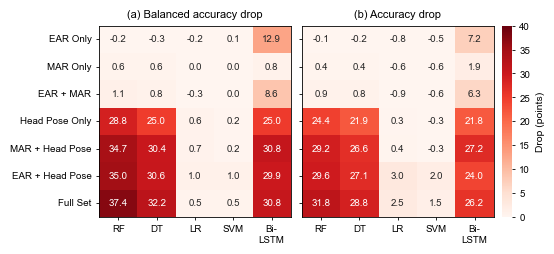

In [16]:
short = {"Random Forest": "RF", "Decision Tree": "DT", "Logistic Regression": "LR", "Linear SVM": "SVM"}
columns = list(short.values()) + ["Bi-LSTM"]

def drop_matrix(metric):
    m = pd.DataFrame(index=list(FEATURE_SETS), columns=columns, dtype=float)
    for clf, label in short.items():
        b = static_random_frame[static_random_frame["Classifier"] == clf].set_index("Feature Set")[metric]
        c = static_held_out[static_held_out["Classifier"] == clf].set_index("Feature Set")[metric]
        m[label] = (b - c).loc[list(FEATURE_SETS)] * 100
    b = bilstm_random_window.set_index("Feature Set")[metric]
    c = bilstm_held_out.set_index("Feature Set")[metric]
    m["Bi-LSTM"] = (b - c).loc[list(FEATURE_SETS)] * 100
    return m

drop_ba, drop_acc = drop_matrix("Balanced Accuracy"), drop_matrix("Accuracy")
print("Balanced accuracy drop (points)")
print(drop_ba.round(1).to_string())

style = {"font.size": 7.5, "axes.titlesize": 8, "axes.labelsize": 7.5,
         "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
         "axes.linewidth": 0.6, "lines.linewidth": 1.0, "patch.linewidth": 0.5,
         "grid.linewidth": 0.4, "lines.markersize": 3, "errorbar.capsize": 2,
         "xtick.major.width": 0.6, "ytick.major.width": 0.6,
         "xtick.major.size": 2.5, "ytick.major.size": 2.5,
         "axes.titleweight": "normal", "pdf.fonttype": 42}
with plt.rc_context(style):
    fig, axes = plt.subplots(1, 3, figsize=(5.43, 2.43), gridspec_kw={"width_ratios": [1, 1, 0.05]},
                             constrained_layout=True)
    for ax, mat, title in [(axes[0], drop_ba, "(a) Balanced accuracy drop"), (axes[1], drop_acc, "(b) Accuracy drop")]:
        sns.heatmap(mat, annot=True, fmt=".1f", cmap="Reds", vmin=0, vmax=40,
                    cbar=(ax is axes[0]), cbar_ax=axes[2] if ax is axes[0] else None,
                    linewidths=0, annot_kws={"size": 7}, ax=ax)
        ax.set_title(title)
        ax.set_xticklabels(["RF", "DT", "LR", "SVM", "Bi-\nLSTM"], rotation=0)
        ax.tick_params(length=2)
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(0.6)
    axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0)
    axes[1].set_yticklabels([])
    axes[2].set_ylabel("Drop (points)")
    axes[2].tick_params(length=2)
    plt.savefig(os.path.join(FIG_DIR, "drop_random_to_subject_held_out.png"), dpi=600)
    plt.show()

### 7.2 Training impurity importance and held-out permutation importance
Impurity importance comes from the training data of the subject-held-out Full Set Random Forest. Permutation importance shuffles one feature at a time across the held-out drivers (10 shuffles per feature) and records the drop in balanced accuracy. The permutation results are computed once from the saved model and then loaded.

Feature  Impurity importance  Permutation drop (points)  Std over 10 shuffles (points)
    Yaw               0.2466                    -0.8986                         0.0816
  Pitch               0.2297                    -2.3331                         0.1074
   Roll               0.2262                    -0.5510                         0.0569
    EAR               0.1743                     2.7161                         0.1233
    MAR               0.1232                    -0.5972                         0.0421


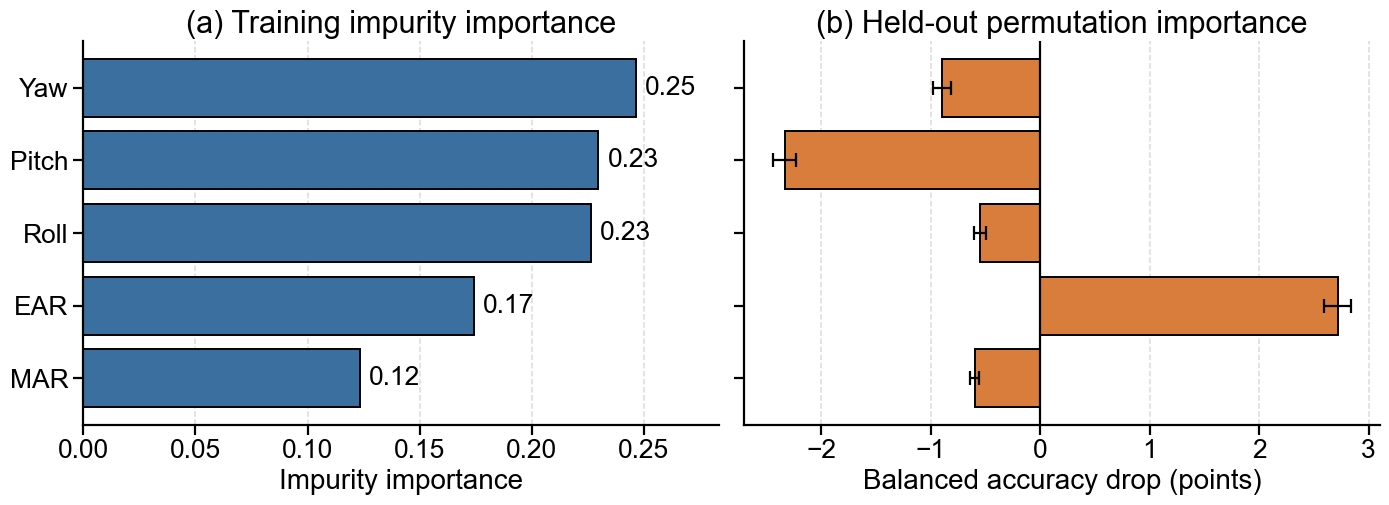

In [17]:
path = os.path.join(RESULTS_DIR, "permutation_importance.csv")
if RUN_TRAINING or not os.path.exists(path):
    clf = joblib.load(os.path.join(MODELS_DIR, "random_forest_full_set.joblib"))
    _, test = subject_split(uta)
    print(f"Held-out balanced accuracy of the saved model: "
          f"{balanced_accuracy_score(test['Target'], clf.predict(test[FEATURES])):.4f}")
    perm = permutation_importance(clf, test[FEATURES], test['Target'], scoring="balanced_accuracy",
                                  n_repeats=10, random_state=SEED, n_jobs=1)
    pd.DataFrame({
        "Feature": FEATURES,
        "Impurity importance": clf.feature_importances_,
        "Permutation drop (points)": perm.importances_mean * 100,
        "Std over 10 shuffles (points)": perm.importances_std * 100,
    }).sort_values("Impurity importance", ascending=False).to_csv(path, index=False)

imp_df = pd.read_csv(path)
print(imp_df.round(4).to_string(index=False))

feat_order = imp_df["Feature"].tolist()[::-1]
r = imp_df.set_index("Feature").loc[feat_order]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.15), sharey=True)
axes[0].barh(feat_order, r["Impurity importance"], color="#3B6FA0", edgecolor="black", linewidth=1.4)
for y, v in enumerate(r["Impurity importance"]):
    axes[0].text(v + 0.004, y, f"{v:.2f}", va="center", fontsize=19)
axes[0].set_xlabel("Impurity importance", fontsize=20)
axes[0].set_title("(a) Training impurity importance", fontsize=22)
axes[0].set_xlim(0, r["Impurity importance"].max() * 1.15)

axes[1].barh(feat_order, r["Permutation drop (points)"], xerr=r["Std over 10 shuffles (points)"],
             color="#D97D3D", edgecolor="black", linewidth=1.4, capsize=5,
             error_kw={"elinewidth": 1.6, "capthick": 1.6})
axes[1].axvline(0, color="black", linewidth=1.6)
axes[1].set_xlabel("Balanced accuracy drop (points)", fontsize=20)
axes[1].set_title("(b) Held-out permutation importance", fontsize=22)

for ax in axes:
    ax.grid(axis="x", linestyle="--", linewidth=1.1, alpha=0.45)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.6)
    ax.spines["bottom"].set_linewidth(1.6)
    ax.tick_params(labelsize=19, width=1.6, length=7)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "feature_importance_impurity_vs_permutation.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

### 7.3 Bi-LSTM loss curves for EAR + MAR and the Full Set
Training and validation loss under the random-window split and on held-out drivers. The dotted line is the constant-prediction reference: the loss of a model that always predicts the drowsy share of the validation windows.

Full Set, Random-window Split: lowest validation loss 0.2648 at epoch 20, final 0.2648, constant-prediction loss 0.6350
Full Set, Subject-held-out Split: lowest validation loss 0.6297 at epoch 1, final 1.2061, constant-prediction loss 0.6291
EAR + MAR, Random-window Split: lowest validation loss 0.4988 at epoch 20, final 0.4988, constant-prediction loss 0.6350
EAR + MAR, Subject-held-out Split: lowest validation loss 0.5724 at epoch 2, final 0.6896, constant-prediction loss 0.6291


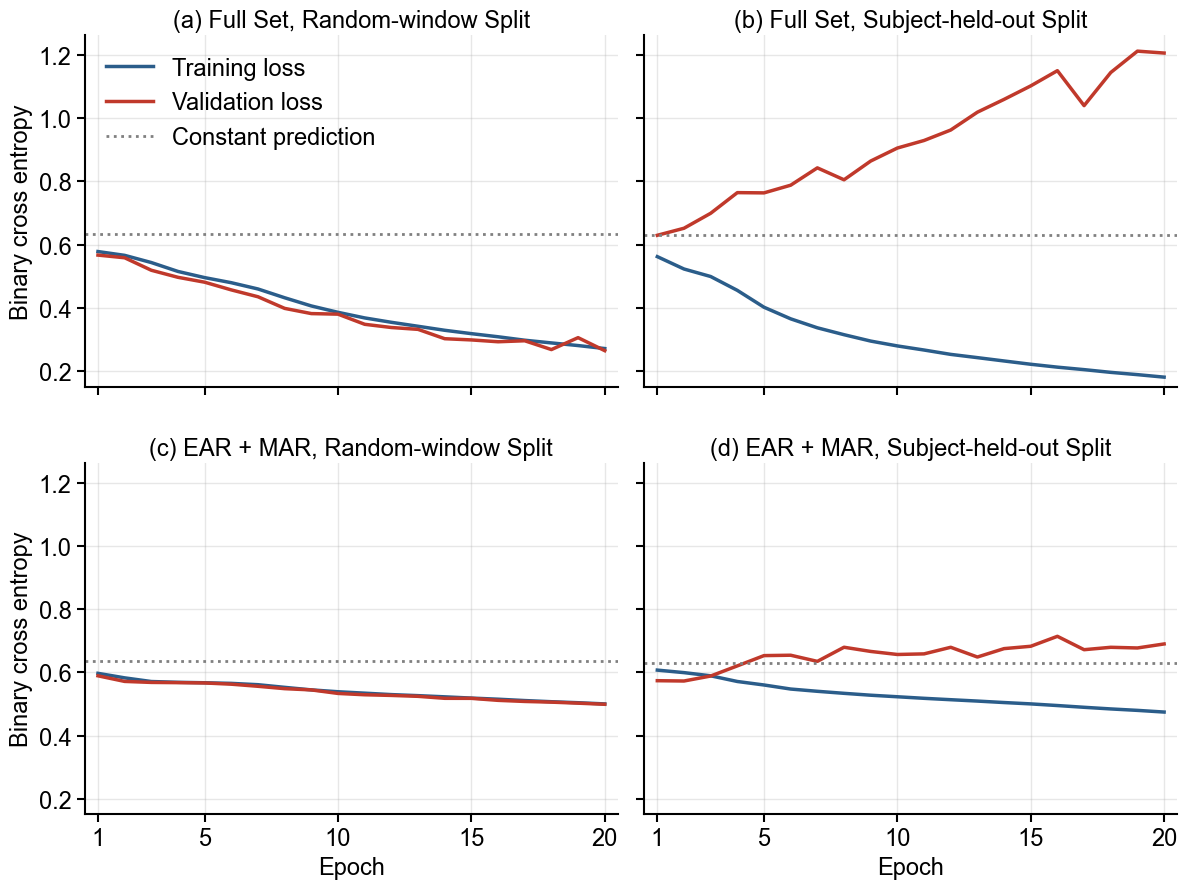

In [18]:
def history(protocol, set_name):
    return pd.read_csv(os.path.join(HIST_DIR, f"bilstm_{protocol}_{file_key(set_name)}_history.csv"))

panels = [
    [("random_window", "Full Set", PRIOR_RANDOM_WINDOW, "(a) Full Set, Random-window Split"),
     ("held_out", "Full Set", PRIOR_VALIDATION, "(b) Full Set, Subject-held-out Split")],
    [("random_window", "EAR + MAR", PRIOR_RANDOM_WINDOW, "(c) EAR + MAR, Random-window Split"),
     ("held_out", "EAR + MAR", PRIOR_VALIDATION, "(d) EAR + MAR, Subject-held-out Split")],
]
hists = {(p, s): history(p, s) for row in panels for p, s, _, _ in row}
y_min = min(h["loss"].min() for h in hists.values()) - 0.03
y_max = max(h["val_loss"].max() for h in hists.values()) + 0.05

FS = 17
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
for i in range(2):
    for j in range(2):
        protocol, set_name, prior, title = panels[i][j]
        h = hists[(protocol, set_name)]
        ep = range(1, len(h) + 1)
        ax = axes[i, j]
        ax.plot(ep, h["loss"], label="Training loss", color="#2B5D8A", lw=2.5)
        ax.plot(ep, h["val_loss"], label="Validation loss", color="#C0392B", lw=2.5)
        ax.axhline(constant_prediction_loss(prior), color="gray", linestyle=":", linewidth=2, label="Constant prediction")
        ax.set_title(title, fontsize=FS)
        ax.set_xlim(0.5, 20.5)
        ax.set_xticks([1, 5, 10, 15, 20])
        ax.set_ylim(y_min, y_max)
        ax.grid(True, linewidth=1, alpha=0.3)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_linewidth(1.5)
        ax.spines["bottom"].set_linewidth(1.5)
        ax.tick_params(labelsize=FS, width=1.5, length=6)
        if i == 1:
            ax.set_xlabel("Epoch", fontsize=FS)
        if j == 0:
            ax.set_ylabel("Binary cross entropy", fontsize=FS)
        print(f"{title.split(') ')[1]}: lowest validation loss {h['val_loss'].min():.4f} at epoch "
              f"{int(h['val_loss'].idxmin()) + 1}, final {h['val_loss'].iloc[-1]:.4f}, "
              f"constant-prediction loss {constant_prediction_loss(prior):.4f}")
axes[0, 0].legend(loc="upper left", fontsize=FS, frameon=False)

plt.tight_layout(h_pad=3)
plt.savefig(os.path.join(FIG_DIR, "bilstm_loss_curves.png"), dpi=600, bbox_inches="tight", facecolor="white")
plt.show()

### 7.4 Bi-LSTM loss curves for the remaining feature sets

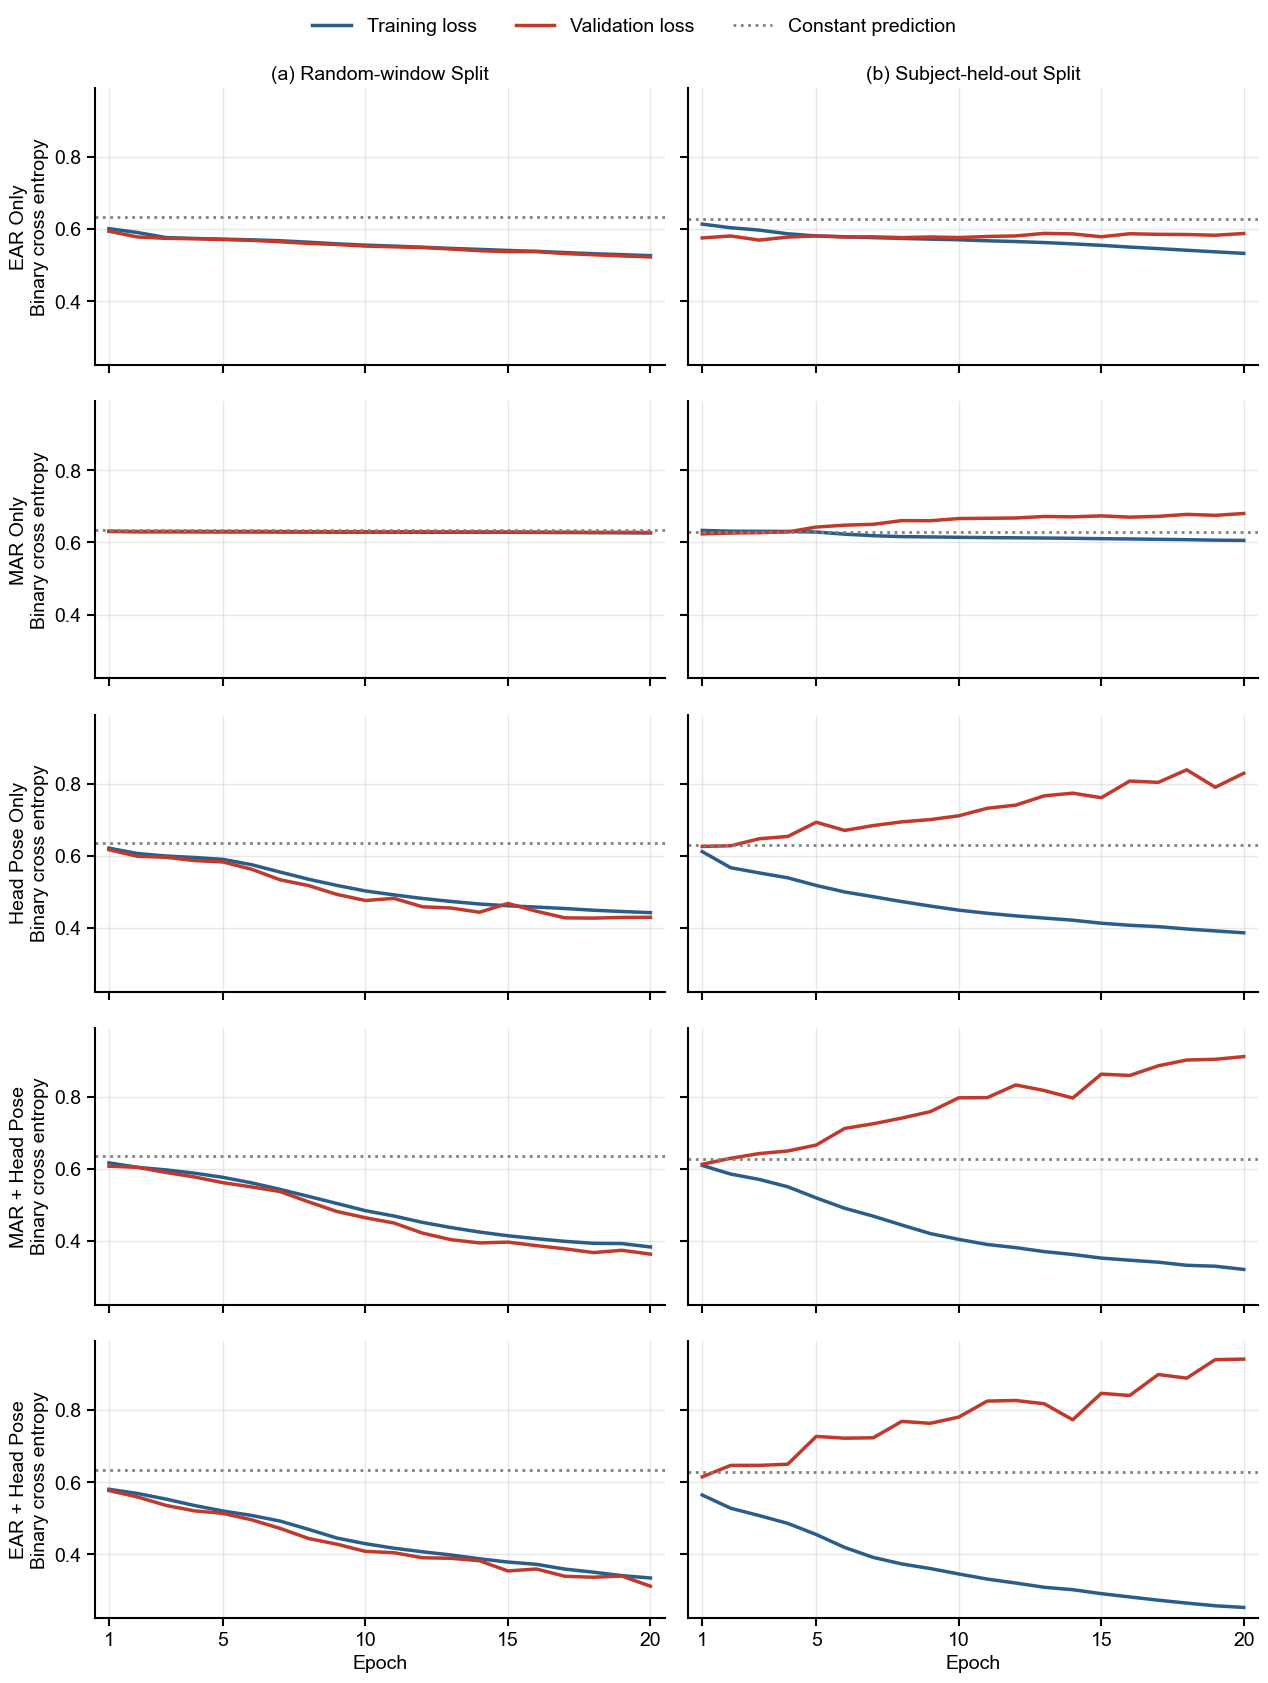

    Feature Set                  Split  Lowest validation loss  Epoch of lowest  Final validation loss  Constant-prediction loss
       EAR Only    Random-window Split                  0.5231               20                 0.5231                    0.6350
       EAR Only Subject-held-out Split                  0.5698                3                 0.5881                    0.6291
       MAR Only    Random-window Split                  0.6276               20                 0.6276                    0.6350
       MAR Only Subject-held-out Split                  0.6239                1                 0.6804                    0.6291
 Head Pose Only    Random-window Split                  0.4270               18                 0.4294                    0.6350
 Head Pose Only Subject-held-out Split                  0.6260                1                 0.8288                    0.6291
MAR + Head Pose    Random-window Split                  0.3640               20                 0

In [19]:
rest = [s for s in FEATURE_SETS if s not in ("EAR + MAR", "Full Set")]
curves = {(p, s): history(p, s) for s in rest for p in ("random_window", "held_out")}
y_min = min(h["loss"].min() for h in curves.values()) - 0.03
y_max = max(h["val_loss"].max() for h in curves.values()) + 0.05

FS = 14
cols = [("random_window", "(a) Random-window Split", PRIOR_RANDOM_WINDOW),
        ("held_out", "(b) Subject-held-out Split", PRIOR_VALIDATION)]
fig, axes = plt.subplots(len(rest), 2, figsize=(12.78, 16.88), sharex=True, sharey=True)
summary = []
for i, set_name in enumerate(rest):
    for j, (protocol, col_label, prior) in enumerate(cols):
        h = curves[(protocol, set_name)]
        ep = range(1, len(h) + 1)
        ax = axes[i, j]
        ax.plot(ep, h["loss"], color="#2B5D8A", lw=2.5, label="Training loss")
        ax.plot(ep, h["val_loss"], color="#C0392B", lw=2.5, label="Validation loss")
        ax.axhline(constant_prediction_loss(prior), color="gray", linestyle=":", linewidth=2, label="Constant prediction")
        ax.set_xlim(0.5, 20.5)
        ax.set_xticks([1, 5, 10, 15, 20])
        ax.set_ylim(y_min, y_max)
        ax.grid(True, linewidth=1, alpha=0.3)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_linewidth(1.5)
        ax.spines["bottom"].set_linewidth(1.5)
        ax.tick_params(labelsize=FS, width=1.5, length=6)
        if i == 0:
            ax.set_title(col_label, fontsize=FS)
        if i == len(rest) - 1:
            ax.set_xlabel("Epoch", fontsize=FS)
        if j == 0:
            ax.set_ylabel(f"{set_name}\nBinary cross entropy", fontsize=FS)
        summary.append({"Feature Set": set_name, "Split": col_label[4:],
                        "Lowest validation loss": round(h["val_loss"].min(), 4),
                        "Epoch of lowest": int(h["val_loss"].idxmin()) + 1,
                        "Final validation loss": round(h["val_loss"].iloc[-1], 4),
                        "Constant-prediction loss": round(constant_prediction_loss(prior), 4)})

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, fontsize=FS, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=[0, 0, 1, 0.97], h_pad=2)
plt.savefig(os.path.join(FIG_DIR, "bilstm_loss_curves_other_feature_sets.png"), dpi=600, bbox_inches="tight", facecolor="white")
plt.show()
print(pd.DataFrame(summary).to_string(index=False))

### 7.5 Held-out balanced accuracy across models and feature sets
Balanced accuracy of the four static classifiers and the Bi-LSTM on the 12 held-out drivers. The dashed line marks 50 percent.

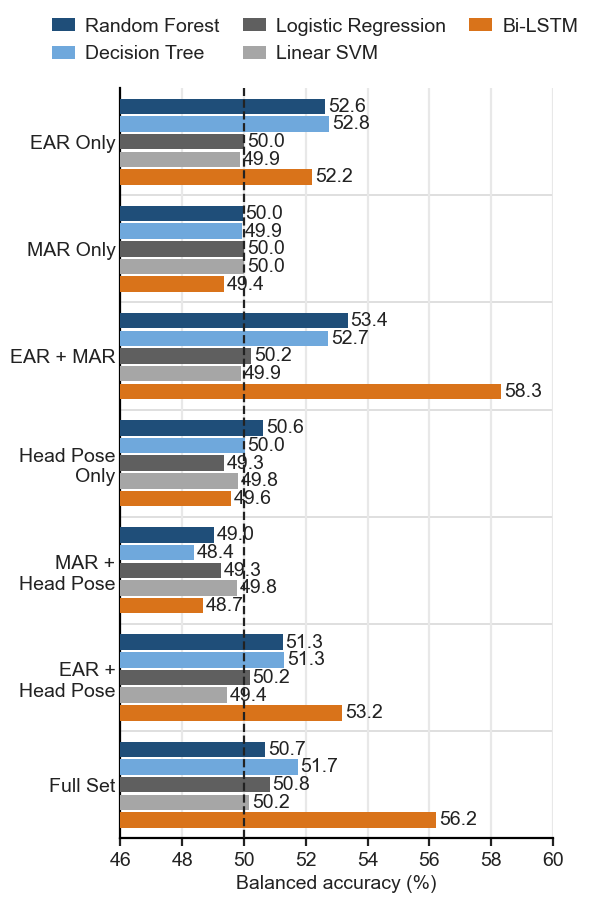

In [20]:
all_models = pd.concat([static_held_out, bilstm_held_out.assign(Classifier="Bi-LSTM")], ignore_index=True)
order = list(FEATURE_SETS)
labels = ["EAR Only", "MAR Only", "EAR + MAR", "Head Pose\nOnly", "MAR +\nHead Pose", "EAR +\nHead Pose", "Full Set"]
classifiers = ["Random Forest", "Decision Tree", "Logistic Regression", "Linear SVM", "Bi-LSTM"]
palette = ["#1F4E79", "#6FA8DC", "#5F5F5F", "#A6A6A6", "#D9731A"]

FS = 14
with plt.rc_context({"font.size": FS, "text.color": "#222222", "axes.labelcolor": "#222222",
                     "xtick.color": "#222222", "ytick.color": "#222222"}):
    y = np.arange(len(order))
    step, height = 0.165, 0.145
    fig, ax = plt.subplots(figsize=(6, 9.25))
    for i, (clf, color) in enumerate(zip(classifiers, palette)):
        vals = all_models[all_models["Classifier"] == clf].set_index("Feature Set").loc[order, "Balanced Accuracy"] * 100
        bars = ax.barh(y + (i - 2) * step, vals.values, height, label=clf, color=color, zorder=3)
        ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=FS)
    ax.axvline(50, color="#222222", linestyle="--", linewidth=1.6, zorder=4)
    for k in range(len(order) - 1):
        ax.axhline(k + 0.5, color="#D9D9D9", linewidth=1.2, zorder=1)
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=FS)
    ax.set_xlabel("Balanced accuracy (%)", fontsize=FS)
    ax.set_xlim(46, 60)
    ax.set_xticks(range(46, 61, 2))
    ax.grid(axis="x", color="#E8E8E8", linewidth=1.6, zorder=0)
    ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.45, 1.01), frameon=False,
              fontsize=FS, handlelength=1.2, columnspacing=1.2, handletextpad=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.6)
    ax.spines["bottom"].set_linewidth(1.6)
    ax.tick_params(axis="y", length=0, labelsize=FS)
    ax.tick_params(axis="x", width=1.6, length=6, labelsize=FS)
    ax.set_ylim(len(order) - 0.5, -0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "held_out_balanced_accuracy_by_model.png"), dpi=600, bbox_inches="tight", facecolor="white")
    plt.show()

### 7.6 Confusion matrices on held-out drivers (Full Set)
Rows are the true class and columns the predicted class (alert, drowsy). The static classifiers are scored on frames and the Bi-LSTM on windows. One colour scale, from zero to the largest count in the first figure, is shared by both figures.

Random Forest       TN  12142 FP  31671 FN  23879 TP  66856 | balanced accuracy 50.70 | alert recall 27.71 | drowsy recall 73.68
Linear SVM          TN   3305 FP  40508 FN   6537 TP  84198 | balanced accuracy 50.17 | alert recall 7.54 | drowsy recall 92.80
Bi-LSTM             TN  16556 FP  26897 FN  23107 TP  66908 | balanced accuracy 56.22 | alert recall 38.10 | drowsy recall 74.33
Logistic Regression TN   5969 FP  37844 FN  10841 TP  79894 | balanced accuracy 50.84 | alert recall 13.62 | drowsy recall 88.05
Decision Tree       TN  16148 FP  27665 FN  30274 TP  60461 | balanced accuracy 51.75 | alert recall 36.86 | drowsy recall 66.63


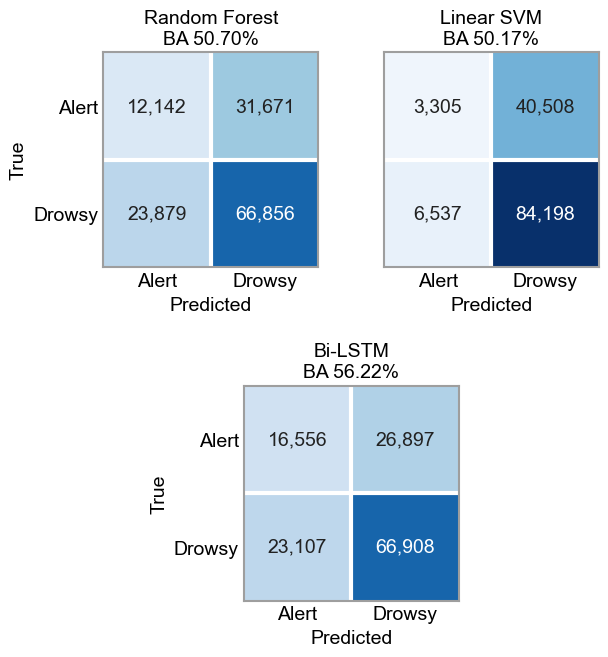

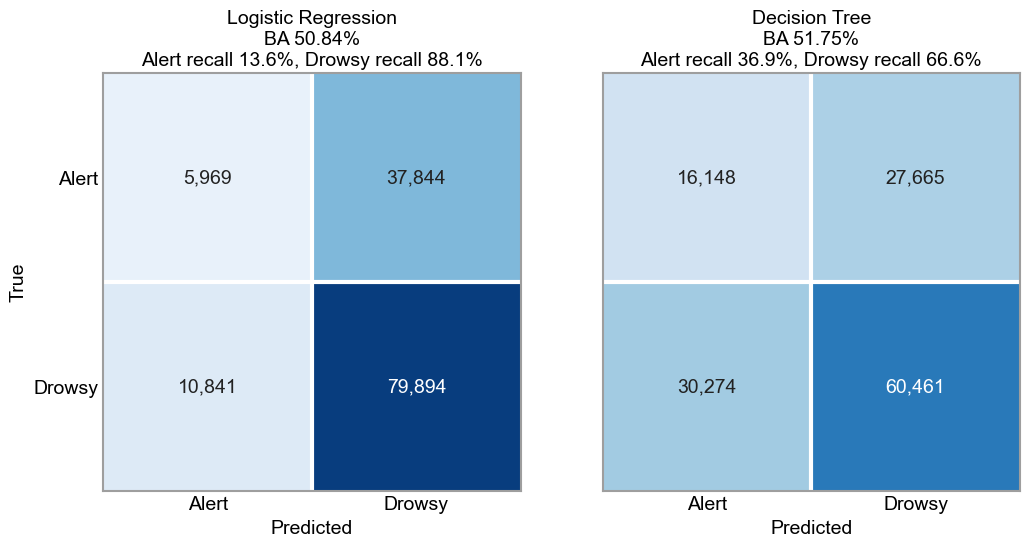

In [21]:
_, test = subject_split(uta)
y_frames = test['Target'].values
y_windows, subj_windows = window_labels(test)

def held_out_preds(clf_name):
    key = clf_name.lower().replace(" ", "_")
    return pd.read_csv(os.path.join(PRED_DIR, f"{key}_held_out_full_set_preds.csv"))["pred"].values

matrices = {
    "Random Forest": confusion_matrix(y_frames, held_out_preds("Random Forest")),
    "Linear SVM": confusion_matrix(y_frames, held_out_preds("Linear SVM")),
    "Bi-LSTM": confusion_matrix(y_windows, np.load(os.path.join(PRED_DIR, "bilstm_held_out_full_set_preds.npy"))),
    "Logistic Regression": confusion_matrix(y_frames, held_out_preds("Logistic Regression")),
    "Decision Tree": confusion_matrix(y_frames, held_out_preds("Decision Tree")),
}
VMAX = max(matrices[m].max() for m in ["Random Forest", "Linear SVM", "Bi-LSTM"])
FS = 14
classes = ["Alert", "Drowsy"]

def draw_matrix(ax, name, cm, title_lines, vmax):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=vmax)
    for r_ in range(2):
        for c_ in range(2):
            ax.text(c_, r_, f"{cm[r_, c_]:,}", ha="center", va="center", fontsize=FS,
                    color="white" if cm[r_, c_] > 0.6 * vmax else "#222222")
    ax.axhline(0.5, color="white", linewidth=3)
    ax.axvline(0.5, color="white", linewidth=3)
    ax.set_title("\n".join([name] + title_lines), fontsize=FS)
    ax.set_xticks([0, 1]); ax.set_xticklabels(classes, fontsize=FS)
    ax.set_yticks([0, 1]); ax.set_yticklabels(classes, fontsize=FS)
    ax.set_xlabel("Predicted", fontsize=FS)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_color("#9E9E9E"); spine.set_linewidth(1.5)

def recalls(cm):
    alert, drowsy = 100 * cm[0, 0] / cm[0].sum(), 100 * cm[1, 1] / cm[1].sum()
    return alert, drowsy, (alert + drowsy) / 2

for name, cm in matrices.items():
    alert, drowsy, ba = recalls(cm)
    print(f"{name:19s} TN {cm[0, 0]:6d} FP {cm[0, 1]:6d} FN {cm[1, 0]:6d} TP {cm[1, 1]:6d} | "
          f"balanced accuracy {ba:.2f} | alert recall {alert:.2f} | drowsy recall {drowsy:.2f}")

fig = plt.figure(figsize=(6.56, 7.12))
gs = fig.add_gridspec(2, 4, hspace=0.55, wspace=0.6)
axes = [fig.add_subplot(gs[0, 0:2]), fig.add_subplot(gs[0, 2:4]), fig.add_subplot(gs[1, 1:3])]
for ax, name in zip(axes, ["Random Forest", "Linear SVM", "Bi-LSTM"]):
    draw_matrix(ax, name, matrices[name], [f"BA {recalls(matrices[name])[2]:.2f}%"], VMAX)
axes[0].set_ylabel("True", fontsize=FS)
axes[2].set_ylabel("True", fontsize=FS)
axes[1].set_yticklabels([])
plt.savefig(os.path.join(FIG_DIR, "confusion_held_out_full_set.png"), dpi=600, bbox_inches="tight", facecolor="white")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10.8, 5.3))
for ax, name in zip(axes, ["Logistic Regression", "Decision Tree"]):
    alert, drowsy, ba = recalls(matrices[name])
    draw_matrix(ax, name, matrices[name],
                [f"BA {ba:.2f}%", f"Alert recall {alert:.1f}%, Drowsy recall {drowsy:.1f}%"], VMAX)
axes[0].set_ylabel("True", fontsize=FS)
axes[1].set_yticklabels([])
plt.tight_layout(w_pad=3)
plt.savefig(os.path.join(FIG_DIR, "confusion_held_out_full_set_lr_dt.png"), dpi=600, bbox_inches="tight", facecolor="white")
plt.show()

### 7.7 Confusion matrices on NTHU-DDD (Full Set)
The Full Set static classifiers applied to NTHU-DDD without refitting. The counts follow from the saved recalls and the class sizes. One colour scale, from zero to the largest count in this figure, is shared by the four panels.

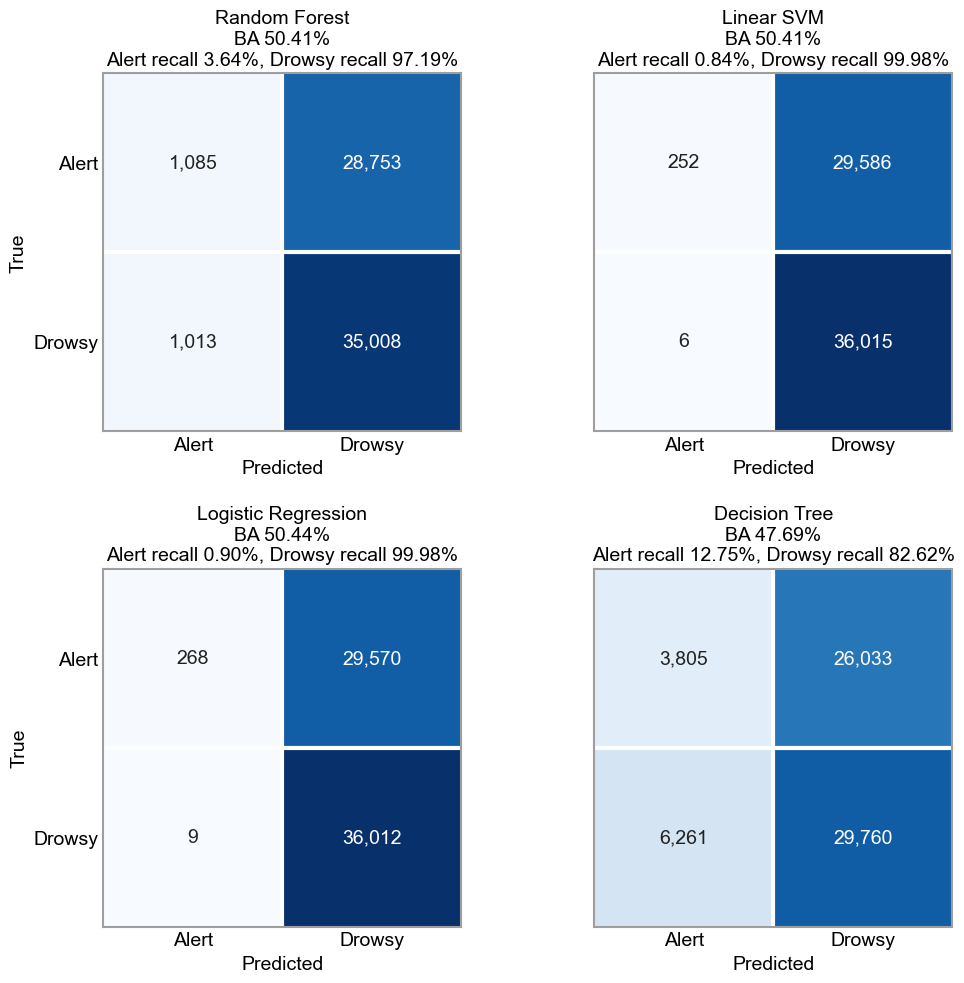

In [22]:
n_alert, n_drowsy = int((nthu['Target'] == 0).sum()), int((nthu['Target'] == 1).sum())
full = static_nthu[static_nthu["Feature Set"] == "Full Set"].set_index("Classifier")
nthu_matrices = {}
for name in ["Random Forest", "Linear SVM", "Logistic Regression", "Decision Tree"]:
    tn = int(round(full.loc[name, "Alert Recall"] * n_alert))
    tp = int(round(full.loc[name, "Drowsy Recall"] * n_drowsy))
    nthu_matrices[name] = np.array([[tn, n_alert - tn], [n_drowsy - tp, tp]])
VMAX_NTHU = max(cm.max() for cm in nthu_matrices.values())

fig, axes = plt.subplots(2, 2, figsize=(10.8, 9.94))
for ax, (name, cm) in zip(axes.ravel(), nthu_matrices.items()):
    alert, drowsy, ba = recalls(cm)
    draw_matrix(ax, name, cm, [f"BA {ba:.2f}%", f"Alert recall {alert:.2f}%, Drowsy recall {drowsy:.2f}%"], VMAX_NTHU)
for row in range(2):
    axes[row, 0].set_ylabel("True", fontsize=FS)
    axes[row, 1].set_yticklabels([])
plt.tight_layout(w_pad=3, h_pad=2)
plt.savefig(os.path.join(FIG_DIR, "confusion_nthu_ddd_full_set.png"), dpi=600, bbox_inches="tight", facecolor="white")
plt.show()

### 7.8 Driver-level bootstrap intervals
The 12 held-out drivers are resampled with replacement 10,000 times, and balanced accuracy is recomputed from the pooled confusion counts of each resample. Paired comparisons use the same resampled drivers for both models. The intervals are the 2.5th to 97.5th percentiles; they reflect variation across test drivers only, not retraining or alternative partitions.

In [23]:
subjects = sorted(TEST_SUBJECTS, key=int)
subj_frames = test['Subject'].values

def counts_by_subject(y, p, subj):
    out = np.zeros((len(subjects), 4))
    for k, s in enumerate(subjects):
        m = subj == s
        yt, yp = y[m], p[m]
        out[k] = [((yt == 0) & (yp == 0)).sum(), ((yt == 0) & (yp == 1)).sum(),
                  ((yt == 1) & (yp == 0)).sum(), ((yt == 1) & (yp == 1)).sum()]
    return out

def ba_from_counts(c):
    with np.errstate(divide="ignore", invalid="ignore"):
        return 0.5 * (c[..., 3] / (c[..., 3] + c[..., 2]) + c[..., 0] / (c[..., 0] + c[..., 1]))

rf_ear_mar = pd.read_csv(os.path.join(PRED_DIR, "random_forest_held_out_ear_mar_preds.csv"))["pred"].values
models = {
    "Random Forest, EAR + MAR": (y_frames, rf_ear_mar, subj_frames),
    "Random Forest, Full Set": (y_frames, held_out_preds("Random Forest"), subj_frames),
    "Bi-LSTM, EAR + MAR": (y_windows, np.load(os.path.join(PRED_DIR, "bilstm_held_out_ear_mar_preds.npy")), subj_windows),
    "Bi-LSTM, Full Set": (y_windows, np.load(os.path.join(PRED_DIR, "bilstm_held_out_full_set_preds.npy")), subj_windows),
}
counts = {name: counts_by_subject(*args) for name, args in models.items()}
point = {name: ba_from_counts(c.sum(axis=0)) for name, c in counts.items()}

rng = np.random.default_rng(SEED)
idx = rng.integers(0, len(subjects), size=(10_000, len(subjects)))
boot = {name: ba_from_counts(c[idx].sum(axis=1)) for name, c in counts.items()}

intervals = pd.DataFrame([{"Model": name, "Balanced Accuracy (%)": round(point[name] * 100, 2),
                           "95% CI lower (%)": round(np.nanpercentile(boot[name], 2.5) * 100, 2),
                           "95% CI upper (%)": round(np.nanpercentile(boot[name], 97.5) * 100, 2)} for name in models])
pairs = [("Bi-LSTM minus Random Forest, EAR + MAR", "Bi-LSTM, EAR + MAR", "Random Forest, EAR + MAR"),
         ("Bi-LSTM minus Random Forest, Full Set", "Bi-LSTM, Full Set", "Random Forest, Full Set"),
         ("Bi-LSTM EAR + MAR minus Full Set", "Bi-LSTM, EAR + MAR", "Bi-LSTM, Full Set"),
         ("Random Forest EAR + MAR minus Full Set", "Random Forest, EAR + MAR", "Random Forest, Full Set")]
differences = pd.DataFrame([{"Comparison": label,
                             "Difference (points)": round((point[a] - point[b]) * 100, 2),
                             "95% CI lower": round(np.nanpercentile(boot[a] - boot[b], 2.5) * 100, 2),
                             "95% CI upper": round(np.nanpercentile(boot[a] - boot[b], 97.5) * 100, 2),
                             "Share of draws above 0": round(float(np.nanmean(boot[a] - boot[b] > 0)), 3)}
                            for label, a, b in pairs])
intervals.to_csv(os.path.join(RESULTS_DIR, "bootstrap_intervals.csv"), index=False)
differences.to_csv(os.path.join(RESULTS_DIR, "bootstrap_differences.csv"), index=False)
print(intervals.to_string(index=False))
print()
print(differences.to_string(index=False))

                   Model  Balanced Accuracy (%)  95% CI lower (%)  95% CI upper (%)
Random Forest, EAR + MAR                  53.35             50.53             56.15
 Random Forest, Full Set                  50.70             42.19             59.03
      Bi-LSTM, EAR + MAR                  58.32             52.15             64.44
       Bi-LSTM, Full Set                  56.22             47.41             65.39

                            Comparison  Difference (points)  95% CI lower  95% CI upper  Share of draws above 0
Bi-LSTM minus Random Forest, EAR + MAR                 4.97          1.16          8.72                   0.995
 Bi-LSTM minus Random Forest, Full Set                 5.52         -0.85         12.73                   0.953
      Bi-LSTM EAR + MAR minus Full Set                 2.11         -5.53         10.45                   0.701
Random Forest EAR + MAR minus Full Set                 2.66         -4.32          9.62                   0.775


### 7.9 Balanced accuracy per held-out driver
Balanced accuracy of the Random Forest and the Bi-LSTM on each of the 12 held-out drivers, for all seven feature sets. Random Forest predictions that were not saved during training are regenerated by refitting on the same 48 training drivers, after checking that a refit reproduces the saved EAR + MAR predictions. The per-driver results are computed once and then loaded.

                                mean    std    min    max  Drivers above 50  Pooled BA
Family        Feature Set                                                             
Random Forest EAR Only         52.27   2.92  47.61  57.39                 9      52.63
Bi-LSTM       EAR Only         52.34   6.46  44.07  68.06                 7      52.21
Random Forest MAR Only         49.97   0.90  48.35  51.34                 7      49.96
Bi-LSTM       MAR Only         49.39   2.22  44.48  52.28                 6      49.37
Random Forest EAR + MAR        53.05   4.82  44.67  59.95                 8      53.35
Bi-LSTM       EAR + MAR        58.33  10.80  44.87  70.43                 7      58.32
Random Forest Head Pose Only   49.73  12.01  33.39  77.29                 4      50.62
Bi-LSTM       Head Pose Only   48.33  13.51  29.14  72.11                 4      49.59
Random Forest MAR + Head Pose  48.00  12.75  31.75  77.57                 4      49.04
Bi-LSTM       MAR + Head Pose  47.46  10.16

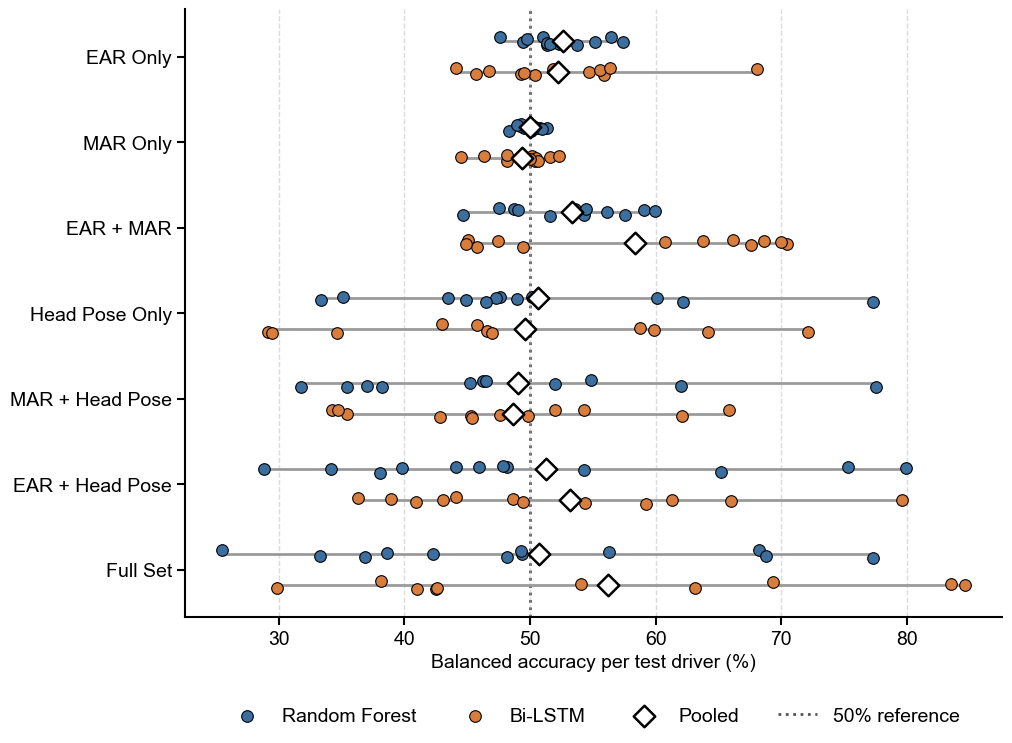

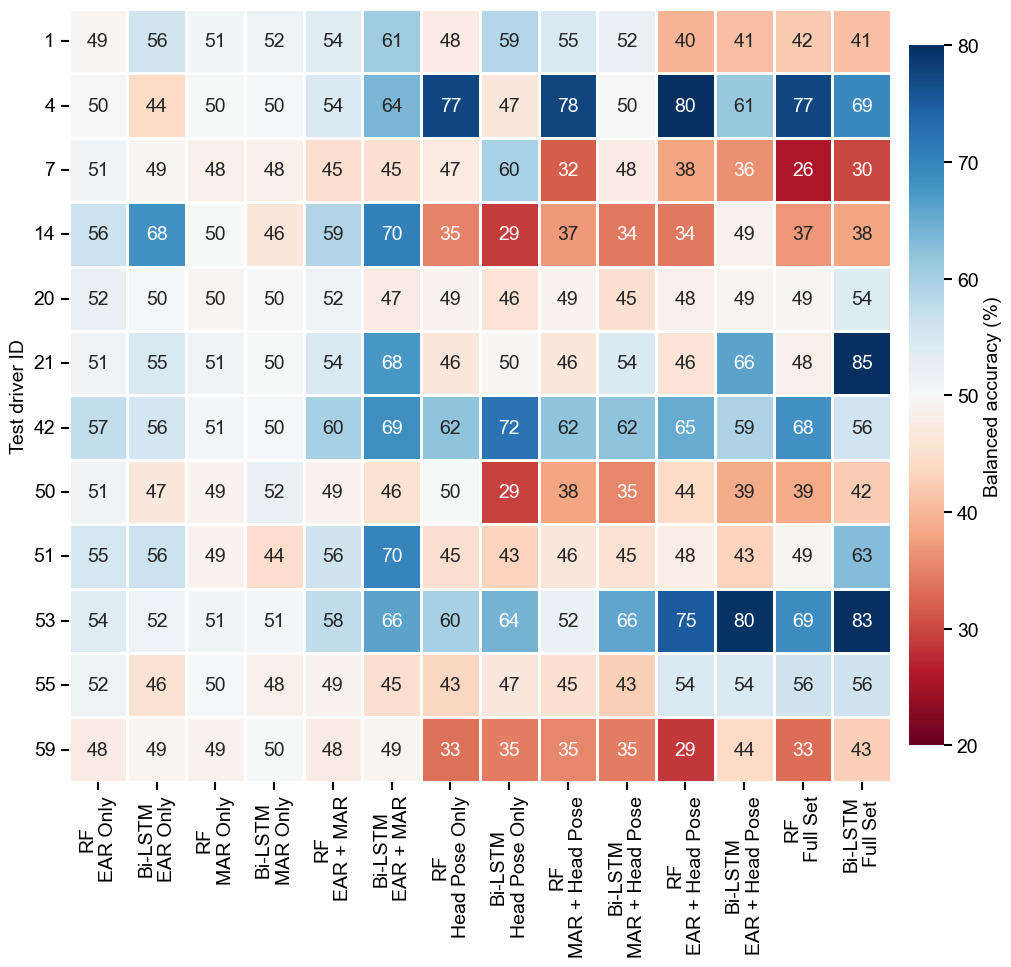

In [24]:
path = os.path.join(RESULTS_DIR, "per_driver_balanced_accuracy.csv")
if RUN_TRAINING or not os.path.exists(path):
    train, _ = subject_split(uta)
    refit_checked = False
    rows = []
    for set_name, cols in FEATURE_SETS.items():
        rf_path = os.path.join(PRED_DIR, f"random_forest_held_out_{file_key(set_name)}_preds.csv")
        if not os.path.exists(rf_path):
            if not refit_checked:
                refit = make_rf().fit(train[['EAR', 'MAR']], train['Target']).predict(test[['EAR', 'MAR']])
                assert np.array_equal(refit, rf_ear_mar), "A refit does not reproduce the saved EAR + MAR predictions"
                refit_checked = True
            pred = make_rf().fit(train[cols], train['Target']).predict(test[cols])
            pd.Series(pred, name="pred").to_csv(rf_path, index=False)
        rf_pred = pd.read_csv(rf_path)["pred"].values
        lstm_pred = np.load(os.path.join(PRED_DIR, f"bilstm_held_out_{file_key(set_name)}_preds.npy"))
        for family, c in [("Random Forest", counts_by_subject(y_frames, rf_pred, subj_frames)),
                          ("Bi-LSTM", counts_by_subject(y_windows, lstm_pred, subj_windows))]:
            for k, s in enumerate(subjects):
                rows.append({"Family": family, "Feature Set": set_name, "Subject": int(s),
                             "TN": c[k, 0], "FP": c[k, 1], "FN": c[k, 2], "TP": c[k, 3],
                             "BA": 100 * ba_from_counts(c[k])})
    pd.DataFrame(rows).to_csv(path, index=False)

per_driver = pd.read_csv(path)
pooled = {(fam, s): 100 * ba_from_counts(g[["TN", "FP", "FN", "TP"]].sum().values)
          for (fam, s), g in per_driver.groupby(["Family", "Feature Set"])}
assert abs(pooled[("Random Forest", "Full Set")] - point["Random Forest, Full Set"] * 100) < 1e-9
summary = per_driver.groupby(["Family", "Feature Set"])["BA"].agg(["mean", "std", "min", "max"])
summary["Drivers above 50"] = (per_driver[per_driver["BA"] > 50].groupby(["Family", "Feature Set"]).size()
                               .reindex(summary.index).fillna(0).astype(int))
summary["Pooled BA"] = pd.Series(pooled)
order = [(fam, s) for s in FEATURE_SETS for fam in ["Random Forest", "Bi-LSTM"]]
print(summary.reindex(order).round(2).to_string())

short_family = {"Random Forest": "RF", "Bi-LSTM": "Bi-LSTM"}
fam_color = {"Random Forest": "#3B6FA0", "Bi-LSTM": "#D97D3D"}
fam_offset = {"Random Forest": -0.18, "Bi-LSTM": 0.18}
FS = 14

fig, ax = plt.subplots(figsize=(10.22, 7.5))
jitter = np.random.default_rng(0)
for i, set_name in enumerate(FEATURE_SETS):
    for fam in ["Random Forest", "Bi-LSTM"]:
        vals = per_driver[(per_driver["Family"] == fam) & (per_driver["Feature Set"] == set_name)]["BA"].values
        y0 = i + fam_offset[fam]
        ax.hlines(y0, vals.min(), vals.max(), color="#9A9A9A", linewidth=2, zorder=2)
        ax.scatter(vals, y0 + jitter.uniform(-0.05, 0.05, len(vals)), s=70, color=fam_color[fam],
                   edgecolor="black", linewidth=0.8, zorder=3)
        ax.scatter(pooled[(fam, set_name)], y0, marker="D", s=120, color="white", edgecolor="black",
                   linewidth=1.8, zorder=4)
ax.axvline(50, color="#555555", linestyle=":", linewidth=2, zorder=1)
ax.set_yticks(range(len(FEATURE_SETS)))
ax.set_yticklabels(list(FEATURE_SETS), fontsize=FS)
ax.invert_yaxis()
ax.set_xlabel("Balanced accuracy per test driver (%)", fontsize=FS)
ax.grid(axis="x", linestyle="--", linewidth=1, alpha=0.45, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=FS, width=1.5, length=6)
for fam in fam_color:
    ax.scatter([], [], s=70, color=fam_color[fam], edgecolor="black", linewidth=0.8, label=fam)
ax.scatter([], [], marker="D", s=120, color="white", edgecolor="black", linewidth=1.8, label="Pooled")
ax.plot([], [], color="#555555", linestyle=":", linewidth=2, label="50% reference")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False, fontsize=FS)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "per_driver_spread.png"), dpi=600, bbox_inches="tight", facecolor="white")
plt.show()

cols = [(s, fam) for s in FEATURE_SETS for fam in ["Random Forest", "Bi-LSTM"]]
heat = per_driver.pivot_table(index="Subject", columns=["Feature Set", "Family"], values="BA")[cols].sort_index()
fig, ax = plt.subplots(figsize=(10.22, 9.78))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="RdBu", center=50, vmin=20, vmax=80, linewidths=1,
            linecolor="white", annot_kws={"fontsize": FS}, ax=ax,
            cbar_kws={"label": "Balanced accuracy (%)", "fraction": 0.04, "pad": 0.02})
ax.set_xlabel("")
ax.set_ylabel("Test driver ID", fontsize=FS)
ax.set_xticklabels([f"{short_family[fam]}\n{s}" for s, fam in cols], rotation=90, ha="center", fontsize=FS)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=FS)
ax.tick_params(width=1.5, length=6)
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=FS, width=1.5, length=6)
cbar.set_label("Balanced accuracy (%)", fontsize=FS)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "per_driver_balanced_accuracy.png"), dpi=600, bbox_inches="tight", facecolor="white")
plt.show()

## 8. Repeated grouped partitions and alternative angle encodings
The main comparison uses one partition of each grouped split. This section repeats the subject-held-out comparison over five further partitions and the recording-held-out comparison over five further seeds, and compares the raw Euler angles with two alternative encodings. All runs use the Random Forest of section 5. Results are computed once and then loaded.

### 8.1 Alternative angle encodings
The extracted pitch lies near plus or minus 180 degrees, so a small nod can jump from +179 to -179. Recentred pitch, (pitch mod 360) - 180, maps those values near 0 so they are continuous. The second encoding replaces each angle with its sine and cosine.

In [25]:
uta_enc = uta.copy()
uta_enc['Pitch_c'] = (uta_enc['Pitch'] % 360) - 180
for angle in HEAD_POSE:
    radians = np.deg2rad(uta_enc[angle])
    uta_enc[angle + '_sin'] = np.sin(radians)
    uta_enc[angle + '_cos'] = np.cos(radians)
print(f"Share of frames with pitch within 30 degrees of plus or minus 180: {(uta_enc['Pitch'].abs() > 150).mean():.3f}")

ENCODED_SETS = {
    "EAR + MAR": ['EAR', 'MAR'],
    "Full Set, raw angles": FEATURES,
    "Full Set, recentred pitch": ['EAR', 'MAR', 'Pitch_c', 'Yaw', 'Roll'],
    "Full Set, sin/cos angles": ['EAR', 'MAR', 'Pitch_sin', 'Pitch_cos', 'Yaw_sin', 'Yaw_cos', 'Roll_sin', 'Roll_cos'],
}

def rf_scores(train, test, cols):
    pred = make_rf().fit(train[cols], train['Target']).predict(test[cols])
    return {"Balanced Accuracy": balanced_accuracy_score(test['Target'], pred),
            "Alert Recall": recall_score(test['Target'], pred, pos_label=0),
            "Drowsy Recall": recall_score(test['Target'], pred, pos_label=1)}, pred

Share of frames with pitch within 30 degrees of plus or minus 180: 0.986


### 8.2 Repeated subject-held-out partitions
The 60 drivers are shuffled once (seed 42) and divided into five partitions of 12, so every driver is held out exactly once. EAR + MAR is compared with the Full Set under the three angle encodings, on the main partition and the five further partitions.

In [26]:
shuffled = [str(s) for s in np.random.default_rng(SEED).permutation(np.array(sorted(uta['Subject'].unique(), key=int)))]
PARTITIONS = {"Main paper": set(TEST_SUBJECTS),
              **{f"Partition {k + 1}": set(shuffled[k * 12:(k + 1) * 12]) for k in range(5)}}
for name, drivers in PARTITIONS.items():
    print(f"{name}: {', '.join(sorted(drivers, key=int))}")

path = os.path.join(RESULTS_DIR, "repeated_subject_partitions.csv")
if RUN_TRAINING or not os.path.exists(path):
    rows = []
    for name, drivers in PARTITIONS.items():
        train, test_p = subject_split(uta_enc, drivers)
        for set_name, cols in ENCODED_SETS.items():
            sc, _ = rf_scores(train, test_p, cols)
            rows.append({"Partition": name, "Feature Set": set_name, **sc, "Test Drowsy Share": test_p['Target'].mean()})
    pd.DataFrame(rows).to_csv(path, index=False)

partitions = pd.read_csv(path)
ba = partitions.pivot(index="Partition", columns="Feature Set", values="Balanced Accuracy").loc[list(PARTITIONS), list(ENCODED_SETS)] * 100
ba["Difference"] = ba["Full Set, raw angles"] - ba["EAR + MAR"]
print("\nBalanced accuracy (%) and Full Set (raw angles) minus EAR + MAR (points)")
print(ba.round(2).to_string())
further = ba.drop(index="Main paper")
print("\nMean and SD over partitions 1 to 5:")
print(further.agg(["mean", "std"]).round(2).to_string())
for set_name in [s for s in ENCODED_SETS if s != "EAR + MAR"]:
    d = further[set_name] - further["EAR + MAR"]
    print(f"{set_name} minus EAR + MAR: mean {d.mean():+.2f} points, range {d.min():+.2f} to {d.max():+.2f}, "
          f"higher in {(d > 0).sum()} of 5 partitions")
print(f"Across all six partitions, Full Set (raw angles) minus EAR + MAR ranges from "
      f"{ba['Difference'].min():+.2f} to {ba['Difference'].max():+.2f} points")

Main paper: 1, 4, 7, 14, 20, 21, 42, 50, 51, 53, 55, 59
Partition 1: 6, 8, 18, 19, 25, 28, 29, 40, 45, 51, 56, 60
Partition 2: 5, 21, 26, 30, 32, 38, 43, 49, 50, 53, 55, 58
Partition 3: 4, 10, 16, 17, 22, 24, 27, 31, 33, 35, 41, 57
Partition 4: 1, 7, 11, 12, 20, 23, 36, 39, 42, 47, 52, 54
Partition 5: 2, 3, 9, 13, 14, 15, 34, 37, 44, 46, 48, 59

Balanced accuracy (%) and Full Set (raw angles) minus EAR + MAR (points)
Feature Set  EAR + MAR  Full Set, raw angles  Full Set, recentred pitch  Full Set, sin/cos angles  Difference
Partition                                                                                                    
Main paper       53.35                 50.70                      50.77                     51.11       -2.66
Partition 1      51.93                 52.59                      52.36                     52.28        0.65
Partition 2      51.93                 54.06                      53.43                     53.42        2.13
Partition 3      53.33       

### 8.3 Repeated recording-held-out partitions
Repeats the recording-held-out split with five further seeds for EAR + MAR and the Full Set.

In [27]:
path = os.path.join(RESULTS_DIR, "repeated_recording_partitions.csv")
if RUN_TRAINING or not os.path.exists(path):
    rows = []
    for seed in [SEED] + REPEAT_SEEDS:
        train, test_r = recording_split(uta_enc, seed)
        for set_name in ["EAR + MAR", "Full Set, raw angles"]:
            sc, _ = rf_scores(train, test_r, ENCODED_SETS[set_name])
            rows.append({"Seed": seed, "Feature Set": set_name, **sc, "Test Recordings": test_r['Video_ID'].nunique()})
    pd.DataFrame(rows).to_csv(path, index=False)

repeats = pd.read_csv(path)
piv = repeats.pivot(index="Seed", columns="Feature Set", values="Balanced Accuracy").loc[[SEED] + REPEAT_SEEDS] * 100
piv["Difference"] = piv["Full Set, raw angles"] - piv["EAR + MAR"]
print(piv.round(2).to_string())
further = piv.drop(index=SEED)
print("\nMean of seeds 1 to 5:", further.mean().round(2).to_dict())
print(f"Full Set minus EAR + MAR over seeds 1 to 5: range {further['Difference'].min():+.2f} to "
      f"{further['Difference'].max():+.2f}, higher in {(further['Difference'] > 0).sum()} of 5")

Feature Set  EAR + MAR  Full Set, raw angles  Difference
Seed                                                    
42               50.52                 47.22       -3.30
1                53.15                 52.88       -0.26
2                54.68                 51.22       -3.46
3                51.93                 50.82       -1.11
4                50.18                 49.42       -0.76
5                51.34                 50.15       -1.19

Mean of seeds 1 to 5: {'EAR + MAR': 52.26, 'Full Set, raw angles': 50.9, 'Difference': -1.36}
Full Set minus EAR + MAR over seeds 1 to 5: range -3.46 to -0.26, higher in 0 of 5


### 8.4 Random-frame split with the alternative encodings
Checks whether the large random-frame gain from head pose remains when the angles are recentred or encoded as sine and cosine.

In [28]:
path = os.path.join(RESULTS_DIR, "random_frame_encodings.csv")
if RUN_TRAINING or not os.path.exists(path):
    train, test_f = random_frame_split(uta_enc)
    rows = [{"Feature Set": set_name, **rf_scores(train, test_f, cols)[0]} for set_name, cols in ENCODED_SETS.items()]
    pd.DataFrame(rows).to_csv(path, index=False)

encodings = pd.read_csv(path)
print((encodings.set_index("Feature Set") * 100).round(2).to_string())

                           Balanced Accuracy  Alert Recall  Drowsy Recall
Feature Set                                                              
EAR + MAR                              54.46         29.72          79.20
Full Set, raw angles                   88.12         81.09          95.14
Full Set, recentred pitch              88.18         81.26          95.10
Full Set, sin/cos angles               88.18         81.11          95.25


## 9. Recording-specific information in head-pose features
### 9.1 Between-group variance and identity probe
The share of each feature's variance that lies between recordings and between drivers (eta squared). A Random Forest then predicts the recording (178 classes) or the driver (60 classes) of a frame from EAR + MAR or from head pose alone. Frames are split at random (80/20); 50,000 training and 50,000 test frames are sampled, and leaves hold at least 20 samples, which keeps the multiclass forest small enough for memory.

In [29]:
def between_share(col, group):
    g = uta_enc.groupby(group)[col]
    grand = uta_enc[col].mean()
    return (g.size() * (g.mean() - grand) ** 2).sum() / ((uta_enc[col] - grand) ** 2).sum()

variance = pd.DataFrame({
    "Between recordings": {c: between_share(c, 'Video_ID') for c in ['EAR', 'MAR', 'Pitch_c', 'Yaw', 'Roll']},
    "Between drivers": {c: between_share(c, 'Subject') for c in ['EAR', 'MAR', 'Pitch_c', 'Yaw', 'Roll']},
})
variance.to_csv(os.path.join(RESULTS_DIR, "between_group_variance.csv"))
print("Share of variance between groups (0: none; 1: all)")
print(variance.round(3).to_string())

PROBE_SETS = {
    "EAR + MAR": ['EAR', 'MAR'],
    "Head pose, raw": HEAD_POSE,
    "Head pose, sin/cos": ['Pitch_sin', 'Pitch_cos', 'Yaw_sin', 'Yaw_cos', 'Roll_sin', 'Roll_cos'],
}
path = os.path.join(RESULTS_DIR, "identity_probe.csv")
if RUN_TRAINING or not os.path.exists(path):
    tr_idx, te_idx = train_test_split(uta_enc.index, test_size=0.2, random_state=SEED, shuffle=True)
    tr_idx = pd.Index(np.random.default_rng(SEED).choice(tr_idx, 50_000, replace=False))
    te_idx = pd.Index(np.random.default_rng(7).choice(te_idx, 50_000, replace=False))
    rows = []
    for target, label in [('Video_ID', "Recording"), ('Subject', "Driver")]:
        most_frequent = uta_enc.loc[te_idx, target].value_counts(normalize=True).iloc[0]
        for set_name, cols in PROBE_SETS.items():
            clf = RandomForestClassifier(n_estimators=100, min_samples_leaf=20, random_state=SEED, n_jobs=-1)
            clf.fit(uta_enc.loc[tr_idx, cols], uta_enc.loc[tr_idx, target])
            acc = accuracy_score(uta_enc.loc[te_idx, target], clf.predict(uta_enc.loc[te_idx, cols]))
            rows.append({"Target": label, "Classes": uta_enc[target].nunique(), "Feature Set": set_name,
                         "Accuracy": acc, "Most frequent": most_frequent})
    pd.DataFrame(rows).to_csv(path, index=False)

probe = pd.read_csv(path)
shown = probe.pivot(index="Target", columns="Feature Set", values="Accuracy")[list(PROBE_SETS)] * 100
shown["Most frequent"] = probe.groupby("Target")["Most frequent"].first() * 100
print("\nAccuracy (%) of identifying the recording or driver of a frame")
print(shown.loc[["Recording", "Driver"]].round(2).to_string())

Share of variance between groups (0: none; 1: all)
         Between recordings  Between drivers
EAR                   0.408            0.261
MAR                   0.146            0.058
Pitch_c               0.560            0.346
Yaw                   0.653            0.380
Roll                  0.246            0.168

Accuracy (%) of identifying the recording or driver of a frame
Feature Set  EAR + MAR  Head pose, raw  Head pose, sin/cos  Most frequent
Target                                                                   
Recording         9.35           52.66               53.55           1.12
Driver           12.76           54.90               56.25           2.70


### 9.2 Recording-held-out errors and the driver's training labels
Most drivers contribute one alert recording and two drowsy recordings, so a held-out recording may have training recordings from the same driver with only the opposite label. The test recordings of the main recording-held-out partition are grouped by the labels of the same driver's training recordings, and frame accuracy is reported for each group.

In [30]:
path = os.path.join(RESULTS_DIR, "recording_held_out_by_training_labels.csv")
if RUN_TRAINING or not os.path.exists(path):
    train, test_v = recording_split(uta_enc)
    test_v = test_v.copy()
    training_labels = train.groupby('Subject')['Target'].agg(lambda s: set(s.unique()))

    def relation(row):
        labels = training_labels.get(row['Subject'], set())
        if not labels:
            return "Driver not in training"
        if labels == {row['Target']}:
            return "Same label only"
        if labels == {1 - row['Target']}:
            return "Opposite label only"
        return "Both labels"

    recordings = test_v.groupby('Video_ID')[['Subject', 'Target']].first()
    recordings['Relation'] = recordings.apply(relation, axis=1)
    test_v['Relation'] = test_v['Video_ID'].map(recordings['Relation'])
    rows = []
    for set_name in ["EAR + MAR", "Full Set, raw angles"]:
        _, pred = rf_scores(train, test_v, ENCODED_SETS[set_name])
        test_v['Correct'] = pred == test_v['Target'].values
        for rel, g in test_v.groupby('Relation'):
            rows.append({"Feature Set": set_name, "Relation": rel, "Recordings": g['Video_ID'].nunique(),
                         "Frames": len(g), "Frame Accuracy": g['Correct'].mean()})
    pd.DataFrame(rows).to_csv(path, index=False)

by_labels = pd.read_csv(path)
table = by_labels.pivot(index="Relation", columns="Feature Set", values="Frame Accuracy") * 100
table.insert(0, "Recordings", by_labels.groupby("Relation")["Recordings"].first())
table.insert(1, "Frames", by_labels.groupby("Relation")["Frames"].first())
order = ["Opposite label only", "Both labels", "Same label only", "Driver not in training"]
print(table.loc[order].round(1).to_string())

Feature Set             Recordings  Frames  EAR + MAR  Full Set, raw angles
Relation                                                                   
Opposite label only             16   55714       58.7                  50.0
Both labels                     13   39224       68.8                  77.4
Same label only                  2    5424       51.0                  44.7
Driver not in training           5   18081       50.2                  50.4


### 9.3 Head-pose angles by class and by recording
Top row: frame densities for alert and drowsy frames. Bottom row: the median of each of the 178 recordings, sorted, with bars from the 25th to the 75th percentile. Axes span the 1st to 99th percentile of frames, so a few roll values near plus or minus 180 degrees fall outside.

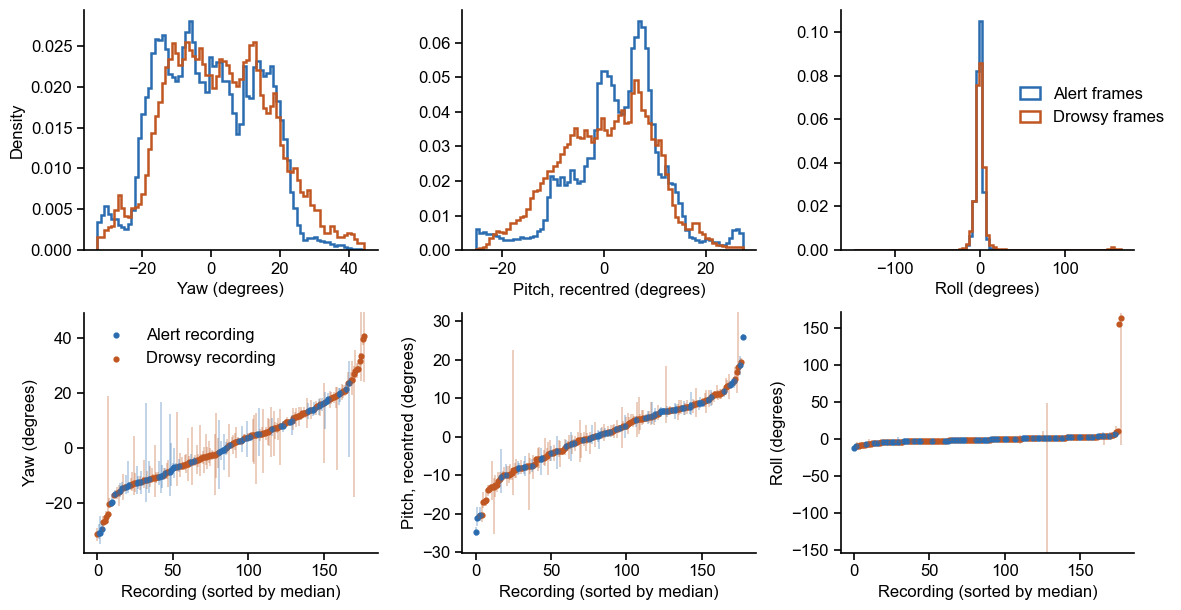

Mean of the recording medians by label (degrees)
         Yaw  Pitch_c  Roll
Target                     
Alert  -1.42     1.95 -0.74
Drowsy  2.89     0.05  2.07
Standard deviation across recordings (degrees): {'Yaw': 14.23, 'Pitch_c': 8.87, 'Roll': 17.21}


In [31]:
FS = 12
ANGLES = [('Yaw', 'Yaw (degrees)'), ('Pitch_c', 'Pitch, recentred (degrees)'), ('Roll', 'Roll (degrees)')]
COLOURS = {0: '#2b6cb0', 1: '#c05621'}
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for j, (a, lab) in enumerate(ANGLES):
    lo, hi = uta_enc[a].quantile([0.01, 0.99])
    bins = np.linspace(lo, hi, 80)
    ax = axes[0, j]
    for t, name in [(0, 'Alert'), (1, 'Drowsy')]:
        ax.hist(uta_enc.loc[uta_enc['Target'] == t, a], bins=bins, density=True, histtype='step', lw=1.8,
                color=COLOURS[t], label=f'{name} frames')
    ax.set_xlabel(lab, fontsize=FS)
    ax.set_ylabel('Density' if j == 0 else '', fontsize=FS)
    if j == 2:
        ax.legend(frameon=False, fontsize=FS, loc='center left', bbox_to_anchor=(0.56, 0.6), handlelength=1.2)
    q = uta_enc.groupby('Video_ID')[a].quantile([0.25, 0.5, 0.75]).unstack()
    q['Target'] = uta_enc.groupby('Video_ID')['Target'].first()
    q = q.sort_values(0.5).reset_index(drop=True)
    ax = axes[1, j]
    for t in [1, 0]:
        s = q[q['Target'] == t]
        ax.vlines(s.index, s[0.25], s[0.75], color=COLOURS[t], alpha=0.35, lw=1.2)
        ax.scatter(s.index, s[0.5], s=12, color=COLOURS[t], label='Alert recording' if t == 0 else 'Drowsy recording')
    ax.set_ylim(lo - 5, hi + 5)
    ax.set_xlabel('Recording (sorted by median)', fontsize=FS)
    ax.set_ylabel(lab, fontsize=FS)
    if j == 0:
        h, l = ax.get_legend_handles_labels()
        ax.legend(h[::-1], l[::-1], frameon=False, fontsize=FS, loc='upper left')
for ax in axes.ravel():
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_linewidth(1.2)
    ax.tick_params(labelsize=FS, width=1.2, length=5)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "head_pose_by_class_and_recording.png"), dpi=600, bbox_inches="tight", facecolor="white")
plt.show()

medians = uta_enc.groupby('Video_ID').agg(Target=('Target', 'first'), Yaw=('Yaw', 'median'),
                                         Pitch_c=('Pitch_c', 'median'), Roll=('Roll', 'median'))
print("Mean of the recording medians by label (degrees)")
print(medians.groupby('Target')[['Yaw', 'Pitch_c', 'Roll']].mean().round(2).rename(index={0: 'Alert', 1: 'Drowsy'}))
print("Standard deviation across recordings (degrees):", medians[['Yaw', 'Pitch_c', 'Roll']].std().round(2).to_dict())